# Model Evaluation: MinMax, Outer 5 / Inner 5, 50 Runs

Focused final analysis notebook.

Settings:

- Input: `../preprocessed_data/omics_aibl_demo_clean_imputed.csv`
- Feature names: `../preprocessed_data/feature_names_clean.xlsx`
- Scaling: MinMax
- Nested CV: `outer_n_split = 5`, `inner_n_split = 5`
- Repeats: `n_repeats = 50`
- With feature selection: LR L1
- Without embedded feature selection: LR L2

Outputs focus on performance tables, AUC plots, ROC curves, and LR L1 feature-selection/coefficient results.


In [ ]:
import random
import re
import itertools
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import MinMaxScaler

import utility
importlib.reload(utility)

RANDOM_STATE = 42
N_REPEATS = 50
OUTER_N_SPLIT = 5
INNER_N_SPLIT = 5
SCALING_METHOD = 'minmax'

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

RESULT_DIR = Path('../results')
PLOT_DIR = Path('../plots')
RESULT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

RUN_TAG = 'minmax_outer5_inner5_50run'

# Manuscript/display renaming only. Raw feature IDs are kept for modelling and joins.
features_to_remove_after_cleanup = {
    'Citroside A',
    "threo-1-(p-Hydroxyphenyl)propylene glycol 4'-glucoside",
}


def strip_single_digit_suffix(name):
    if not isinstance(name, str):
        return name
    return re.sub(r'\.\d$', '', name)


MANUSCRIPT_FEATURE_NAME_MAP = {
    '2_5-Dihydroxypyridine': 'dihydroxypyridine',
    '2,5-Dihydroxypyridine': 'dihydroxypyridine',
    '6beta-acetoxy-24-methylcholestan-3beta_5alpha_22R_24-tetrol': 'acetylated polyhydroxy-ergostanoid',
    '6beta-acetoxy-24-methylcholestan-3beta,5alpha,22R,24-tetrol': 'acetylated polyhydroxy-ergostanoid',
    '7beta-acetoxy-gorgostan-3beta_5alpha_6beta-triol': 'acetylated polyhydroxy-ergostanoid',
    "6-Butyryl-5_7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin": '4-phenylcoumarin',
    "6-Butyryl-5,7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin": '4-phenylcoumarin',
    'Aminoadipic acid': 'aminoadipic acid',
    'cyclopentanehexanoic acid': 'oxo-hexadecanoic acid',
    'Cyclopentanehexanoic acid': 'oxo-hexadecanoic acid',
    'Cys/Asp/Asp/Thr/Thr': 'sulfur-containing pentapeptide',
    'DG(22:5/22:6/0:0)': 'DG(44:11)',
    'Dihomocholic acid': 'dihomocholic acid',
    'epithio-seco-cholestadienetriol S_S-dioxide': '25-hydroxyvitamin D3 3-sulfate',
    'Epithio-seco-cholestadienetriol S,S-dioxide': '25-hydroxyvitamin D3 3-sulfate',
    'FA hydroxy(7:0)': 'hydroxyheptanoic acid',
    'Methylimidazole acetaldehyde (MIA)': 'methylimidazole acetaldehyde (MIA)',
    'N-acetyl-L-2-aminoadipate(2-)': 'N-acetyl-aminoadipic acid',
    'Pyrroline hydroxycarboxylic acid': 'pyrroline hydroxycarboxylic acid',
    'Stoloniferone F': 'unsaturated polyhydroxy-ergostanoid',
    'Sulfonic acid': 'sulfonic acid',
    '{[-3-phenylprop-2-en-1-yl]oxy}sulfonic acid': 'sulfonic acid',
    '3-Isopropyl-2-methoxy-5-methylpyrazine': 'methoxypyrazine',
    'Quinic acid': 'quinic acid',
    'Deoxyribose': 'deoxypentose',
    'Guanosine': 'guanosine',
}


def manuscript_feature_name(value):
    if pd.isna(value):
        return value
    clean_name = strip_single_digit_suffix(str(value))
    return MANUSCRIPT_FEATURE_NAME_MAP.get(clean_name, clean_name)


def add_feature_display_column(df, source_col='Feature', display_col='Feature_Display'):
    out = df.copy()
    if source_col in out.columns:
        out[display_col] = out[source_col].map(manuscript_feature_name)
    return out


def use_feature_display_for_plot(df, source_col='Feature'):
    out = add_feature_display_column(df, source_col=source_col)
    if source_col in out.columns and 'Feature_Display' in out.columns:
        out['Feature_ID'] = out[source_col]
        out[source_col] = out['Feature_Display']
    return out


def manuscript_feature_list(cols):
    return [manuscript_feature_name(col) for col in cols]






## 1. Load Clean Imputed Data



In [2]:
PREPROCESSED_DIR = Path('../preprocessed_data')
FEATURE_NAMES_PATH = PREPROCESSED_DIR / 'feature_names_clean.xlsx'
MODEL_INPUT_PATH = PREPROCESSED_DIR / 'omics_aibl_demo_clean_imputed.csv'
MODEL_READY_PATH = PREPROCESSED_DIR / f'df_model_clean_{RUN_TAG}.csv'

names = pd.read_excel(FEATURE_NAMES_PATH)
keys = names['keys'].dropna().tolist()
label_names = names['label_names'].dropna().tolist()
demographic_cols = names['demographic_cols'].dropna().tolist()
proteomic_cols = names['proteomics_cols'].dropna().tolist()
metabolomics_cols = names['metabolomics_cols'].dropna().tolist()
neuropsychological_cols = names['neuropsychological_cols'].dropna().tolist()

RENAMED_FEATURE_NAMES_PATH = RESULT_DIR / 'feature_names_clean_rename.xlsx'

feature_names_renamed = names.copy()
rename_audit_rows = []

for feature_col in ['proteomics_cols', 'metabolomics_cols']:
    if feature_col not in feature_names_renamed.columns:
        continue

    original_values = feature_names_renamed[feature_col].copy()
    renamed_values = original_values.map(
        lambda value: manuscript_feature_name(value) if pd.notna(value) else value
    )
    feature_names_renamed[feature_col] = renamed_values

    changed = pd.DataFrame({
        'Feature list': feature_col,
        'Original feature name': original_values,
        'Renamed feature name': renamed_values,
    })
    changed = changed[
        changed['Original feature name'].notna()
        & changed['Renamed feature name'].notna()
        & changed['Original feature name'].ne(changed['Renamed feature name'])
    ]
    rename_audit_rows.append(changed)

rename_audit = pd.concat(rename_audit_rows, ignore_index=True) if rename_audit_rows else pd.DataFrame(
    columns=['Feature list', 'Original feature name', 'Renamed feature name']
)

with pd.ExcelWriter(RENAMED_FEATURE_NAMES_PATH, engine='openpyxl') as writer:
    feature_names_renamed.to_excel(writer, sheet_name='feature_names_renamed', index=False)
    rename_audit.to_excel(writer, sheet_name='rename_map', index=False)

print('Saved renamed feature-name workbook:', RENAMED_FEATURE_NAMES_PATH)
print('Renamed proteomics/metabolomics features:', len(rename_audit))

df_omics_full = pd.read_csv(MODEL_INPUT_PATH)
print('Clean-imputed input:', df_omics_full.shape)
print('Input path:', MODEL_INPUT_PATH)



Clean-imputed input: (90, 1804)
Input path: ../preprocessed_data/omics_aibl_demo_clean_imputed.csv


## 2. Clean Checks and MinMax Model Table



In [3]:
def clean_feature_name_list(cols):
    seen = set()
    cleaned = []
    for col in cols:
        new_col = strip_single_digit_suffix(col)
        if new_col in features_to_remove_after_cleanup:
            continue
        if new_col not in seen:
            cleaned.append(new_col)
            seen.add(new_col)
    return cleaned


def collapse_duplicate_columns_after_cleanup(df):
    renamed = df.rename(columns={col: strip_single_digit_suffix(col) for col in df.columns})
    collapsed_parts = []
    collapse_log = []

    for col in pd.unique(renamed.columns):
        block = renamed.loc[:, renamed.columns == col]
        if block.shape[1] == 1:
            collapsed_parts.append(block.iloc[:, 0].rename(col))
            continue

        numeric_block = block.apply(pd.to_numeric, errors='coerce')
        if numeric_block.notna().all().all():
            collapsed = numeric_block.mean(axis=1)
            method = 'mean_numeric'
        else:
            collapsed = block.bfill(axis=1).iloc[:, 0]
            method = 'first_non_missing'
        collapsed_parts.append(collapsed.rename(col))
        collapse_log.append({
            'Feature': col,
            'N columns collapsed': block.shape[1],
            'Original columns': '; '.join(block.columns.tolist()),
            'Method': method,
        })

    collapsed_df = pd.concat(collapsed_parts, axis=1)
    collapse_log_df = pd.DataFrame(collapse_log)
    if not collapse_log_df.empty:
        collapse_log_df = collapse_log_df.sort_values(['N columns collapsed', 'Feature'], ascending=[False, True])
    return collapsed_df, collapse_log_df


def prepare_minmax_dataset(
    df,
    omics_features,
    numeric_demographic_cols,
    keys,
    label_names,
    discrete_demo,
    handedness_col='Demographic.Handedness',
):
    df = df.copy()
    if handedness_col in df.columns:
        one_hot_hand = pd.get_dummies(df[handedness_col], prefix=handedness_col)
    else:
        one_hot_hand = pd.DataFrame(index=df.index)

    scale_cols = [c for c in omics_features if c in df.columns]
    scale_cols += [c for c in numeric_demographic_cols if c in df.columns]
    blocked = set(discrete_demo + keys + label_names + [handedness_col])
    scale_cols = [c for c in scale_cols if c not in blocked]

    scaler = MinMaxScaler()
    scaled = pd.DataFrame(
        scaler.fit_transform(df[scale_cols]),
        columns=scale_cols,
        index=df.index,
    )
    keep_unscaled = df.drop(columns=scale_cols + [handedness_col], errors='ignore')
    return pd.concat([scaled, keep_unscaled, one_hot_hand], axis=1)


proteomic_cols = clean_feature_name_list(proteomic_cols)
metabolomics_cols = clean_feature_name_list(metabolomics_cols)
demographic_cols = clean_feature_name_list(demographic_cols)
neuropsychological_cols = clean_feature_name_list(neuropsychological_cols)
keys = clean_feature_name_list(keys)
label_names = clean_feature_name_list(label_names)

input_suffix_cols = [col for col in df_omics_full.columns if re.search(r'\.\d$', str(col))]
input_removed_features_present = sorted(features_to_remove_after_cleanup.intersection(df_omics_full.columns))
print('Input .digit columns:', len(input_suffix_cols))
print('Requested removed features present in input:', input_removed_features_present)

prepared = utility.prep_omics(df_omics_full.copy())
prepared = prepare_minmax_dataset(
    df=prepared,
    omics_features=proteomic_cols + metabolomics_cols,
    numeric_demographic_cols=[
        'Demographic.Years of Education Exact',
        'Age',
        'Vital Signs.Body Mass Index',
        'Demographic.GDS',
    ],
    discrete_demo=[
        'APOE4',
        'Demographic.Sex',
        'Demographic.Primary Occupation',
        'Demographic.Retirement Status',
        'Demographic.Current Marital Status',
        'Demographic.Country of Birth',
    ] + neuropsychological_cols,
    keys=keys,
    label_names=label_names,
)
prepared['label'] = prepared['label'].astype(int)

df_model_clean, collapsed_feature_log = collapse_duplicate_columns_after_cleanup(prepared)
removed_feature_cols = [col for col in features_to_remove_after_cleanup if col in df_model_clean.columns]
df_model_clean = df_model_clean.drop(columns=removed_feature_cols)

collapsed_feature_log.to_csv(RESULT_DIR / f'{RUN_TAG}_collapsed_feature_log.csv', index=False)
df_model_clean.to_csv(MODEL_READY_PATH, index=False)

remaining_suffix_cols = [col for col in df_model_clean.columns if re.search(r'\.\d$', str(col))]
print('Model table:', df_model_clean.shape)
print('Remaining .digit model columns:', len(remaining_suffix_cols))
print('Requested removed features still present:', sorted(features_to_remove_after_cleanup.intersection(df_model_clean.columns)))
print('Saved:', MODEL_READY_PATH)



Input .digit columns: 0
Requested removed features present in input: []
Model table: (90, 1804)
Remaining .digit model columns: 0
Requested removed features still present: []
Saved: ../preprocessed_data/df_model_clean_minmax_outer5_inner5_50run.csv


## 3. Class Balance and Model Frames



In [4]:
demographic_cols_used = [
    'Demographic.Years of Education Exact',
    'Age',
    'Vital Signs.Body Mass Index',
    'APOE4',
    'Demographic.Sex',
    'Demographic.Handedness_Left',
    'Demographic.Handedness_Right',
    'Demographic.Handedness_Ambidextrous',
]
demographic_cols_used = clean_feature_name_list(demographic_cols_used)

basic_fts = [
    'Demographic.Years of Education Exact',
    'Age',
    'APOE4',
    'Demographic.Sex',
]

feature_set_columns = {
    'Basic': basic_fts,
    'Proteomics': proteomic_cols,
    'Metabolomics': metabolomics_cols,
    'Comprehensive': demographic_cols_used + proteomic_cols + metabolomics_cols + neuropsychological_cols,
}

feature_set_plot_labels = {
    'Basic': 'Basic',
    'Proteomics': 'Proteomics',
    'Metabolomics': 'Metabolomics',
    'Comprehensive': 'Comprehensive',
}


def unique_existing(cols, df):
    seen = set()
    out = []
    missing = []
    for col in cols:
        if col in df.columns and col not in seen:
            out.append(col)
            seen.add(col)
        elif col not in df.columns:
            missing.append(col)
    return out, missing


def build_model_frames(df, feature_cols, keep_sex_in_full=False):
    feature_cols, missing_features = unique_existing(feature_cols, df)
    split_cols, missing_split = unique_existing(feature_cols + ['Demographic.Sex', 'label'], df)
    full_df, male_df, female_df = utility.split_dataset_by_sex(
        df,
        split_cols,
        sex_col='Demographic.Sex',
    )
    if not keep_sex_in_full and 'Demographic.Sex' in full_df.columns:
        full_df = full_df.drop(columns=['Demographic.Sex'])
    return {
        'Full Cohort': full_df,
        'Female': female_df,
        'Male': male_df,
    }, sorted(set(missing_features + missing_split))


model_frames = {}
missing_feature_log = []
for feature_set, cols in feature_set_columns.items():
    frames, missing = build_model_frames(
        df_model_clean,
        cols,
        keep_sex_in_full=(feature_set == 'Basic'),
    )
    model_frames[feature_set] = frames
    for feature in missing:
        missing_feature_log.append({'Feature Set': feature_set, 'Missing Feature': feature})

missing_feature_log_df = pd.DataFrame(missing_feature_log)
missing_feature_log_df.to_csv(RESULT_DIR / f'{RUN_TAG}_missing_features.csv', index=False)

for feature_set, frames in model_frames.items():
    print(f'\n{feature_set}')
    for group, model_df in frames.items():
        print(f'  {group}: {model_df.shape}')


def summarize_class_balance(frames, label_col='label'):
    rows = []
    for group, model_df in frames.items():
        y = model_df[label_col].astype(int)
        counts = y.value_counts().to_dict()
        n_negative = counts.get(0, 0)
        n_positive = counts.get(1, 0)
        total = len(y)
        min_class = min(n_negative, n_positive)
        max_class = max(n_negative, n_positive)
        rows.append({
            'Group': group,
            'N total': total,
            'N amyloid negative': n_negative,
            'N amyloid positive': n_positive,
            'Positive prevalence': n_positive / total if total else np.nan,
            'Minority class N': min_class,
            'Imbalance ratio max/min': max_class / min_class if min_class else np.inf,
            'Majority-class baseline accuracy': max_class / total if total else np.nan,
            'Class weighting used in LR': 'balanced',
        })
    return pd.DataFrame(rows)


class_balance_table = summarize_class_balance(model_frames['Comprehensive'])
class_balance_table.to_csv(RESULT_DIR / f'{RUN_TAG}_class_balance_by_group.csv', index=False)
display(class_balance_table)




Basic
  Full Cohort: (90, 5)
  Female: (50, 4)
  Male: (40, 4)

Proteomics
  Full Cohort: (90, 597)
  Female: (50, 597)
  Male: (40, 597)

Metabolomics
  Full Cohort: (90, 1185)
  Female: (50, 1185)
  Male: (40, 1185)

Comprehensive
  Full Cohort: (90, 1792)
  Female: (50, 1792)
  Male: (40, 1792)


,Group,N total,N amyloid negative,N amyloid positive,Positive prevalence,Minority class N,Imbalance ratio max/min,Majority-class baseline accuracy,Class weighting used in LR
0,Full Cohort,90,55,35,0.388889,35,1.571429,0.611111,balanced
1,Female,50,31,19,0.380000,19,1.631579,0.620000,balanced
2,Male,40,24,16,0.400000,16,1.500000,0.600000,balanced


## 4. Model Grids



In [5]:
lr_l1_param_grid = {
    'C': [0.005, 0.01, 0.02, 0.03, 0.05, 0.075, 0.1, 0.2, 0.3, 0.5, 0.75, 1, 2, 5, 10, 100],
    'penalty': ['l1'],
    'solver': ['liblinear'],
}
lr_l1_param_combinations = list(itertools.product(
    lr_l1_param_grid['C'],
    lr_l1_param_grid['penalty'],
    lr_l1_param_grid['solver'],
))

lr_l2_param_grid = {
    'C': lr_l1_param_grid['C'],
    'penalty': ['l2'],
    'solver': ['liblinear'],
}
lr_l2_param_combinations = list(itertools.product(
    lr_l2_param_grid['C'],
    lr_l2_param_grid['penalty'],
    lr_l2_param_grid['solver'],
))

model_configs = {
    'With FS (LR L1)': {
        'model_name': 'LR L1',
        'param_combinations': lr_l1_param_combinations,
        'feature_selection_label': 'With FS',
    },
    'Without FS (LR L2)': {
        'model_name': 'LR L2',
        'param_combinations': lr_l2_param_combinations,
        'feature_selection_label': 'Without FS',
    },
}

print('LR L1 combinations:', len(lr_l1_param_combinations))
print('LR L2 combinations:', len(lr_l2_param_combinations))


LR L1 combinations: 16
LR L2 combinations: 16


## 5. Run 10 Repeated Nested CV Evaluations

This cell is the main runtime cell. It runs 4 feature sets x 3 groups x 2 model configurations.



In [6]:
def can_run_cv_setting(model_df, outer_n_split, inner_n_split, label_col='label'):
    counts = model_df[label_col].value_counts()
    if len(counts) < 2:
        return False, 'Only one class present.'
    min_class_n = int(counts.min())
    if min_class_n < outer_n_split:
        return False, f'Minimum class count {min_class_n} is smaller than outer_n_split={outer_n_split}.'
    estimated_min_train_class = min_class_n - int(np.ceil(min_class_n / outer_n_split))
    if estimated_min_train_class < inner_n_split:
        return False, (
            f'Estimated minimum inner-training class count {estimated_min_train_class} '
            f'is smaller than inner_n_split={inner_n_split}.'
        )
    return True, 'OK'


all_results = {}
evaluation_frames = []
summary_rows = []
feature_outputs = {}

for config_label, config in model_configs.items():
    for feature_set in ['Basic', 'Proteomics', 'Metabolomics', 'Comprehensive']:
        for group in ['Full Cohort', 'Female', 'Male']:
            model_df = model_frames[feature_set][group]
            run_key = (config_label, feature_set, group)
            can_run, reason = can_run_cv_setting(model_df, OUTER_N_SPLIT, INNER_N_SPLIT)

            if not can_run:
                print(f'Skipping {config_label} | {feature_set} | {group}: {reason}')
                continue

            print(f'Running {config_label} | {feature_set} | {group} | shape={model_df.shape}')
            (results,
             overall_auc,
             median_auc,
             iqr_auc,
             q1q3_auc,
             metrics_summary) = utility.run_multiple_evaluations_parallel(
                model_df,
                'logistic_regression',
                config['param_combinations'],
                n_runs=N_REPEATS,
                inner_n_split=INNER_N_SPLIT,
                outer_n_split=OUTER_N_SPLIT,
                global_seed=RANDOM_STATE,
            )

            auc_scores = utility.extract_results(results, 'auc_scores_fold')
            fold_metrics = utility.extract_results(results, 'fold_metrics')
            y_true = utility.extract_results(results, 'y_true')
            y_pred_prob = utility.extract_results(results, 'y_pred_prob')
            y_pred = utility.extract_results(results, 'y_pred')
            feature_selection_df = utility.extract_results(results, 'feature_selection_df')
            feature_coef_df = utility.extract_results(results, 'feature_coef_df')

            all_results[run_key] = {
                'results': results,
                'overall_auc': overall_auc,
                'median_auc': median_auc,
                'iqr_auc': iqr_auc,
                'q1q3_auc': q1q3_auc,
                'metrics_summary': metrics_summary,
                'auc_scores': auc_scores,
                'fold_metrics': fold_metrics,
                'y_true': y_true,
                'y_pred_prob': y_pred_prob,
                'y_pred': y_pred,
            }
            feature_outputs[run_key] = {
                'feature_selection_df': feature_selection_df,
                'feature_coef_df': feature_coef_df,
            }

            for fold_i, (fold_auc, fold_metric) in enumerate(zip(auc_scores, fold_metrics), start=1):
                evaluation_frames.append({
                    'Feature Selection': config['feature_selection_label'],
                    'Model': config['model_name'],
                    'Config': config_label,
                    'Groups': group,
                    'Features': feature_set_plot_labels[feature_set],
                    'Fold Evaluation': fold_i,
                    'AUC': fold_auc,
                    'Accuracy': fold_metric['accuracy'],
                    'Sensitivity': fold_metric['sensitivity'],
                    'Specificity': fold_metric['specificity'],
                })

            selected_per_run = np.array([r['avg_feature_count'] for r in results])
            summary_rows.append({
                'Feature Selection': config['feature_selection_label'],
                'Model': config['model_name'],
                'Config': config_label,
                'Groups': group,
                'Features': feature_set_plot_labels[feature_set],
                'Sample N': len(model_df),
                'N repeats': N_REPEATS,
                'Outer folds': OUTER_N_SPLIT,
                'Inner folds': INNER_N_SPLIT,
                'Outer CV evaluations': len(auc_scores),
                'Overall AUC': overall_auc,
                'Median AUC': median_auc,
                'AUC Q1': q1q3_auc[0],
                'AUC Q3': q1q3_auc[1],
                'AUC IQR': iqr_auc,
                'Median Accuracy': metrics_summary['accuracy']['median'],
                'Accuracy Q1': metrics_summary['accuracy']['q1'],
                'Accuracy Q3': metrics_summary['accuracy']['q3'],
                'Median Sensitivity': metrics_summary['sensitivity']['median'],
                'Sensitivity Q1': metrics_summary['sensitivity']['q1'],
                'Sensitivity Q3': metrics_summary['sensitivity']['q3'],
                'Median Specificity': metrics_summary['specificity']['median'],
                'Specificity Q1': metrics_summary['specificity']['q1'],
                'Specificity Q3': metrics_summary['specificity']['q3'],
                'Median selected features per run': np.median(selected_per_run),
                'Q1 selected features per run': np.percentile(selected_per_run, 25),
                'Q3 selected features per run': np.percentile(selected_per_run, 75),
            })

combined_evaluation_df = pd.DataFrame(evaluation_frames)
combined_evaluation_summary = pd.DataFrame(summary_rows)

combined_evaluation_df.to_csv(RESULT_DIR / f'{RUN_TAG}_fold_level_metrics_with_without_fs.csv', index=False)
combined_evaluation_summary.to_csv(RESULT_DIR / f'{RUN_TAG}_evaluation_summary_with_without_fs.csv', index=False)
combined_evaluation_summary


Running With FS (LR L1) | Basic | Full Cohort | shape=(90, 5)


Running With FS (LR L1) | Basic | Female | shape=(50, 4)
Running With FS (LR L1) | Basic | Male | shape=(40, 4)
Running With FS (LR L1) | Proteomics | Full Cohort | shape=(90, 597)
Running With FS (LR L1) | Proteomics | Female | shape=(50, 597)
Running With FS (LR L1) | Proteomics | Male | shape=(40, 597)
Running With FS (LR L1) | Metabolomics | Full Cohort | shape=(90, 1185)
Running With FS (LR L1) | Metabolomics | Female | shape=(50, 1185)
Running With FS (LR L1) | Metabolomics | Male | shape=(40, 1185)
Running With FS (LR L1) | Comprehensive | Full Cohort | shape=(90, 1792)
Running With FS (LR L1) | Comprehensive | Female | shape=(50, 1792)
Running With FS (LR L1) | Comprehensive | Male | shape=(40, 1792)
Running Without FS (LR L2) | Basic | Full Cohort | shape=(90, 5)
Running Without FS (LR L2) | Basic | Female | shape=(50, 4)
Running Without FS (LR L2) | Basic | Male | shape=(40, 4)
Running Without FS (LR L2) | Proteomics | Full Cohort | shape=(90, 597)
Running Without FS (LR L2) 

,Feature Selection,Model,Config,Groups,Features,Sample N,N repeats,Outer folds,Inner folds,Outer CV evaluations,...,Accuracy Q3,Median Sensitivity,Sensitivity Q1,Sensitivity Q3,Median Specificity,Specificity Q1,Specificity Q3,Median selected features per run,Q1 selected features per run,Q3 selected features per run
0,With FS,LR L1,With FS (LR L1),Full Cohort,Basic,90,50,5,5,250,...,0.722222,0.500000,0.285714,0.571429,0.818182,0.636364,0.909091,1.5,1.20,1.80
1,With FS,LR L1,With FS (LR L1),Female,Basic,50,50,5,5,250,...,0.800000,0.666667,0.500000,0.750000,0.833333,0.666667,1.000000,2.0,1.80,2.20
2,With FS,LR L1,With FS (LR L1),Male,Basic,40,50,5,5,250,...,0.750000,0.333333,0.000000,0.666667,1.000000,0.762500,1.000000,2.2,1.80,2.60
3,With FS,LR L1,With FS (LR L1),Full Cohort,Proteomics,90,50,5,5,250,...,0.611111,0.000000,0.000000,0.285714,1.000000,0.818182,1.000000,13.6,8.80,19.60
4,With FS,LR L1,With FS (LR L1),Female,Proteomics,50,50,5,5,250,...,0.700000,0.666667,0.250000,1.000000,0.833333,0.500000,1.000000,16.3,12.45,20.90
5,With FS,LR L1,With FS (LR L1),Male,Proteomics,40,50,5,5,250,...,0.750000,0.416667,0.000000,1.000000,1.000000,0.600000,1.000000,9.6,7.80,14.60
6,With FS,LR L1,With FS (LR L1),Full Cohort,Metabolomics,90,50,5,5,250,...,0.722222,0.714286,0.428571,0.857143,0.727273,0.545455,0.909091,39.8,32.85,48.20
7,With FS,LR L1,With FS (LR L1),Female,Metabolomics,50,50,5,5,250,...,0.800000,0.666667,0.500000,0.750000,0.833333,0.517857,1.000000,22.9,18.45,27.95
8,With FS,LR L1,With FS (LR L1),Male,Metabolomics,40,50,5,5,250,...,1.000000,1.000000,0.750000,1.000000,1.000000,0.800000,1.000000,14.8,13.80,17.55
9,With FS,LR L1,With FS (LR L1),Full Cohort,Comprehensive,90,50,5,5,250,...,0.722222,0.714286,0.428571,0.857143,0.727273,0.545455,0.909091,11.0,7.25,14.00


## 6. Manuscript-Ready AUC Tables



In [7]:
def format_auc_interval(row):
    return f"{row['Median AUC']:.3f} [{row['AUC Q1']:.3f}, {row['AUC Q3']:.3f}]"

auc_table = combined_evaluation_summary.copy()
auc_table['Median AUC [Q1, Q3]'] = auc_table.apply(format_auc_interval, axis=1)
auc_table['Sensitivity median [Q1, Q3]'] = auc_table.apply(
    lambda r: f"{r['Median Sensitivity']:.3f} [{r['Sensitivity Q1']:.3f}, {r['Sensitivity Q3']:.3f}]",
    axis=1,
)
auc_table['Specificity median [Q1, Q3]'] = auc_table.apply(
    lambda r: f"{r['Median Specificity']:.3f} [{r['Specificity Q1']:.3f}, {r['Specificity Q3']:.3f}]",
    axis=1,
)
auc_table = auc_table[[
    'Feature Selection', 'Model', 'Groups', 'Features', 'Sample N', 'N repeats',
    'Outer folds', 'Inner folds', 'Outer CV evaluations',
    'Overall AUC', 'Median AUC [Q1, Q3]', 'AUC IQR',
    'Sensitivity median [Q1, Q3]', 'Specificity median [Q1, Q3]',
    'Median selected features per run', 'Q1 selected features per run', 'Q3 selected features per run',
]].sort_values(['Features', 'Groups', 'Feature Selection'])

auc_table.to_csv(RESULT_DIR / f'{RUN_TAG}_auc_table_formatted.csv', index=False)
display(auc_table)

auc_wide = combined_evaluation_summary.pivot_table(
    index=['Groups', 'Features'],
    columns='Feature Selection',
    values='Median AUC',
).reset_index()
if {'With FS', 'Without FS'}.issubset(auc_wide.columns):
    auc_wide['With FS - Without FS'] = auc_wide['With FS'] - auc_wide['Without FS']
auc_wide.to_csv(RESULT_DIR / f'{RUN_TAG}_feature_selection_gain_by_group_feature.csv', index=False)
display(auc_wide)



,Feature Selection,Model,Groups,Features,Sample N,N repeats,Outer folds,Inner folds,Outer CV evaluations,Overall AUC,"Median AUC [Q1, Q3]",AUC IQR,"Sensitivity median [Q1, Q3]","Specificity median [Q1, Q3]",Median selected features per run,Q1 selected features per run,Q3 selected features per run
1,With FS,LR L1,Female,Basic,50,50,5,5,250,0.618214,"0.646 [0.524, 0.786]",0.261905,"0.667 [0.500, 0.750]","0.833 [0.667, 1.000]",2.0,1.80,2.20
13,Without FS,LR L2,Female,Basic,50,50,5,5,250,0.618446,"0.667 [0.500, 0.792]",0.291667,"0.750 [0.500, 1.000]","0.833 [0.667, 1.000]",3.0,3.00,3.00
0,With FS,LR L1,Full Cohort,Basic,90,50,5,5,250,0.577794,"0.578 [0.500, 0.649]",0.149351,"0.500 [0.286, 0.571]","0.818 [0.636, 0.909]",1.5,1.20,1.80
12,Without FS,LR L2,Full Cohort,Basic,90,50,5,5,250,0.585525,"0.545 [0.468, 0.636]",0.168831,"0.571 [0.429, 0.714]","0.727 [0.636, 0.818]",4.0,4.00,4.00
2,With FS,LR L1,Male,Basic,40,50,5,5,250,0.488346,"0.500 [0.400, 0.600]",0.200000,"0.333 [0.000, 0.667]","1.000 [0.762, 1.000]",2.2,1.80,2.60
14,Without FS,LR L2,Male,Basic,40,50,5,5,250,0.524195,"0.565 [0.438, 0.688]",0.250000,"0.667 [0.333, 1.000]","0.800 [0.600, 1.000]",3.0,3.00,3.00
10,With FS,LR L1,Female,Comprehensive,50,50,5,5,250,0.530518,"0.583 [0.458, 0.667]",0.208333,"0.667 [0.500, 0.750]","0.833 [0.667, 1.000]",9.2,5.30,12.35
22,Without FS,LR L2,Female,Comprehensive,50,50,5,5,250,0.607442,"0.625 [0.500, 0.750]",0.250000,"0.750 [0.500, 1.000]","0.833 [0.571, 1.000]",1791.0,1791.00,1791.00
9,With FS,LR L1,Full Cohort,Comprehensive,90,50,5,5,250,0.591493,"0.610 [0.532, 0.701]",0.168831,"0.714 [0.429, 0.857]","0.727 [0.545, 0.909]",11.0,7.25,14.00
21,Without FS,LR L2,Full Cohort,Comprehensive,90,50,5,5,250,0.520669,"0.519 [0.455, 0.610]",0.155844,"0.571 [0.286, 0.857]","0.727 [0.455, 0.909]",1791.0,1791.00,1791.00


Feature Selection,Groups,Features,With FS,Without FS,With FS - Without FS
0,Female,Basic,0.645833,0.666667,-0.020833
1,Female,Comprehensive,0.583333,0.625000,-0.041667
2,Female,Metabolomics,0.523810,0.645833,-0.122024
3,Female,Proteomics,0.523810,0.476190,0.047619
4,Full Cohort,Basic,0.577922,0.545455,0.032468
5,Full Cohort,Comprehensive,0.610390,0.519481,0.090909
6,Full Cohort,Metabolomics,0.597403,0.525974,0.071429
7,Full Cohort,Proteomics,0.500000,0.441558,0.058442
8,Male,Basic,0.500000,0.564583,-0.064583
9,Male,Comprehensive,0.866667,0.400000,0.466667


## 7. Essential Performance Plots

This section saves separate Panel C-style AUC boxplots for the LR L1 model with embedded feature selection and the LR L2 no-feature-selection comparator using `utility.plot_panel_c_boxplot`. It also saves separated median AUC bar summaries with spacing between feature-set bars.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Male_Basic vs. Male_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:6.481e-01 U_stat=3.198e+04
Full Cohort_Basic vs. Full Cohort_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:9.494e-37 U_stat=5.138e+04
Female_Basic vs. Female_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:5.999e-11 U_stat=4.180e+04
Full Cohort_Basic vs. Full Cohort_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:1.255e-01 U_stat=2.878e+04
Female_Basic vs. Female_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:7.509e-13 U_stat=4.282e+04
Male_Basic vs. Male_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:2.100e-61 U_stat=4.678e+03
Male_Basic vs. Male_Comprehensive: Mann-Whitney-Wilcoxon test two-sided, P_val:5.898e-42 U_stat=9.393e+03
Full Cohort_Basic vs. Full Cohort_Comprehe

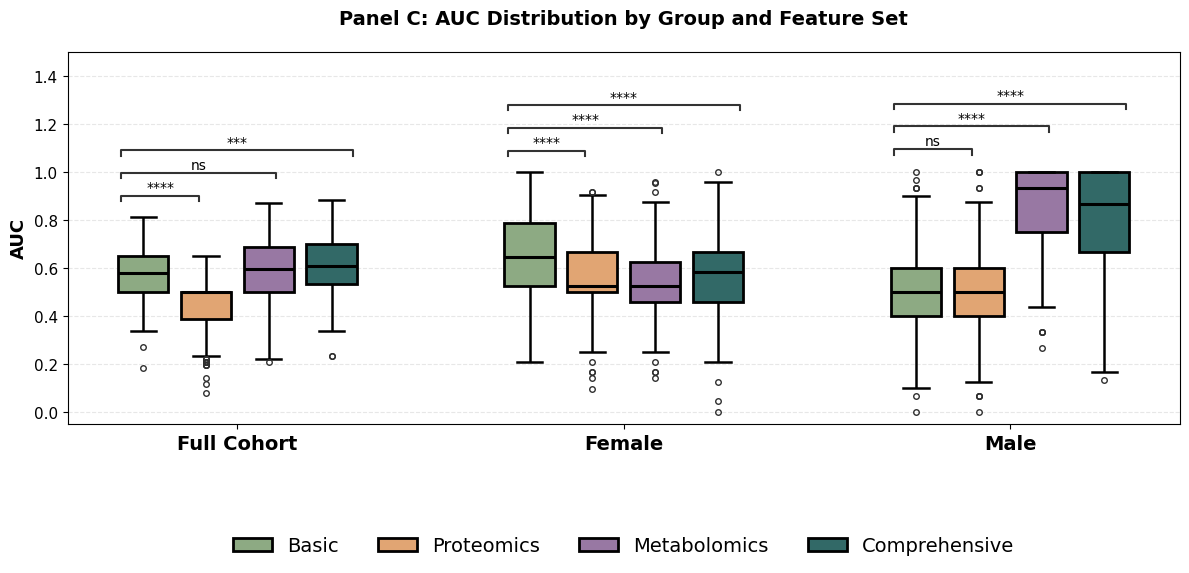

Saved: ../plots/minmax_outer5_inner5_50run_PanelC_Boxplot_With_FS.pdf


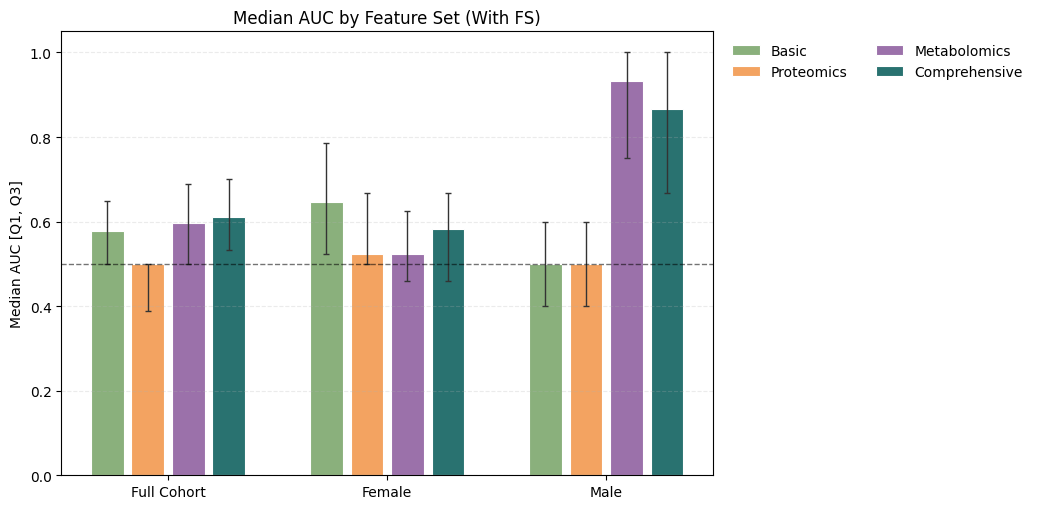

Saved: ../plots/minmax_outer5_inner5_50run_median_AUC_bar_With_FS.pdf
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Male_Basic vs. Male_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:9.083e-42 U_stat=5.310e+04
Full Cohort_Basic vs. Full Cohort_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:2.744e-19 U_stat=4.575e+04
Female_Basic vs. Female_Proteomics: Mann-Whitney-Wilcoxon test two-sided, P_val:6.475e-21 U_stat=4.640e+04
Full Cohort_Basic vs. Full Cohort_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:2.442e-02 U_stat=3.488e+04
Female_Basic vs. Female_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:4.936e-01 U_stat=3.236e+04
Male_Basic vs. Male_Metabolomics: Mann-Whitney-Wilcoxon test two-sided, P_val:4.873e-07 U_stat=3.937e+04
Male_Basic vs. Male_Comprehensive: Mann-Whitney-Wilcoxon test two-sided, P_val

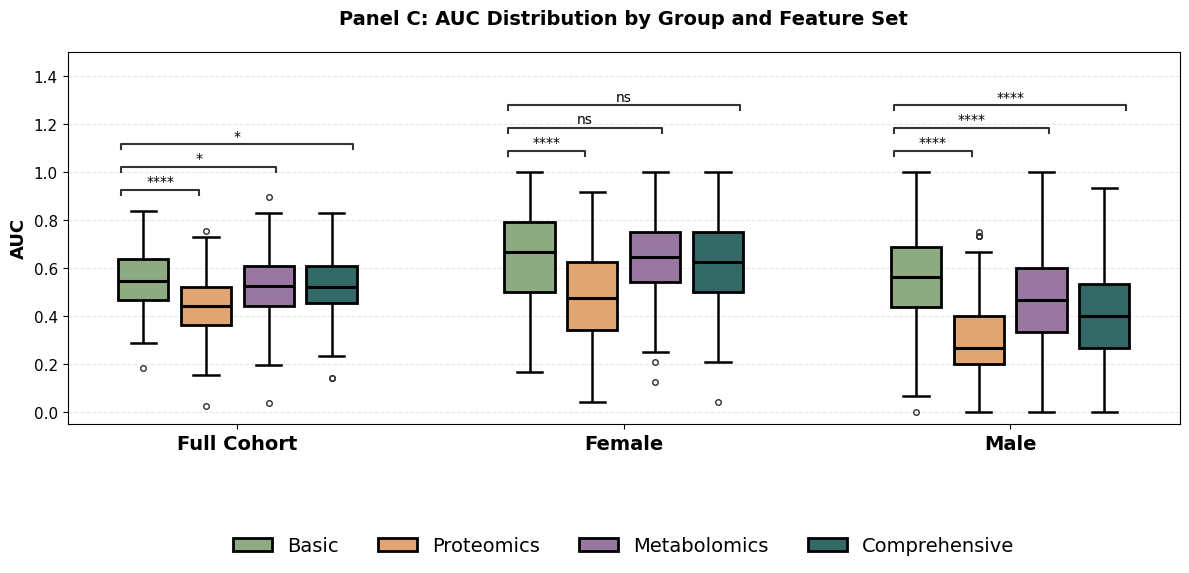

Saved: ../plots/minmax_outer5_inner5_50run_PanelC_Boxplot_Without_FS.pdf


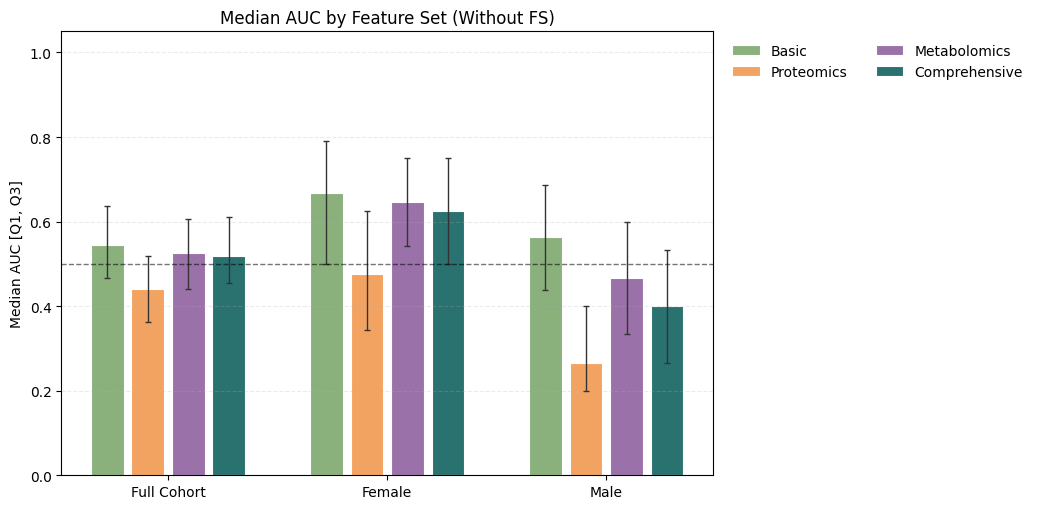

Saved: ../plots/minmax_outer5_inner5_50run_median_AUC_bar_Without_FS.pdf


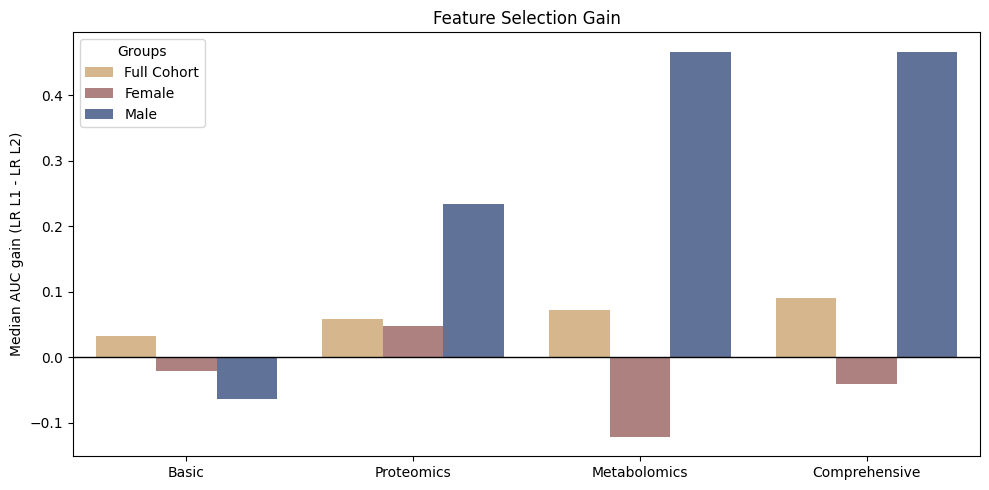

Saved: ../plots/minmax_outer5_inner5_50run_feature_selection_auc_gain.pdf


In [8]:
feature_colors = {
    'Basic': '#8ab07c',
    'Proteomics': '#f3a361',
    'Metabolomics': '#9b71aa',
    'Comprehensive': '#297270',
}
group_order = ['Full Cohort', 'Female', 'Male']
feature_order = ['Basic', 'Proteomics', 'Metabolomics', 'Comprehensive']


def safe_fs_label(label):
    return label.replace(' ', '_').replace('/', '_')


def plot_panel_c_for_fs(fs_label):
    plot_df = combined_evaluation_df[combined_evaluation_df['Feature Selection'].eq(fs_label)].copy()
    if plot_df.empty:
        print(f'No fold-level data available for {fs_label}.')
        return None

    out_path = PLOT_DIR / f'{RUN_TAG}_PanelC_Boxplot_{safe_fs_label(fs_label)}.pdf'
    fig = utility.plot_panel_c_boxplot(
        plot_df,
        save_path=out_path,
        figsize=(12, 6),
    )
    if fig is not None and len(fig.axes) > 0:
        fig.axes[0].set_title(
            f'Panel C: AUC Distribution by Group and Feature Set ({fs_label})',
            fontsize=14,
            fontweight='bold',
            pad=20,
        )
        fig.savefig(out_path, format='pdf', bbox_inches='tight')
    print('Saved:', out_path)
    return fig


def plot_median_auc_bar_for_fs(fs_label):
    plot_df = combined_evaluation_summary[combined_evaluation_summary['Feature Selection'].eq(fs_label)].copy()
    if plot_df.empty:
        print(f'No summary data available for {fs_label}.')
        return None

    x = np.arange(len(group_order))
    bar_width = 0.15
    inner_gap = 0.035
    offsets = (np.arange(len(feature_order)) - (len(feature_order) - 1) / 2) * (bar_width + inner_gap)

    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    for offset, feature in zip(offsets, feature_order):
        feature_df = plot_df[plot_df['Features'].eq(feature)].set_index('Groups')
        medians = [feature_df.loc[group, 'Median AUC'] if group in feature_df.index else np.nan for group in group_order]
        q1 = [feature_df.loc[group, 'AUC Q1'] if group in feature_df.index else np.nan for group in group_order]
        q3 = [feature_df.loc[group, 'AUC Q3'] if group in feature_df.index else np.nan for group in group_order]
        lower = np.array(medians) - np.array(q1)
        upper = np.array(q3) - np.array(medians)
        ax.bar(
            x + offset,
            medians,
            width=bar_width,
            color=feature_colors[feature],
            edgecolor='white',
            linewidth=0.8,
            label=feature,
        )
        ax.errorbar(
            x + offset,
            medians,
            yerr=[lower, upper],
            fmt='none',
            ecolor='#333333',
            elinewidth=1,
            capsize=2.5,
        )

    ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.55)
    ax.set_xticks(x)
    ax.set_xticklabels(group_order)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
    ax.set_ylabel('Median AUC [Q1, Q3]')
    ax.set_title(f'Median AUC by Feature Set ({fs_label})')
    ax.grid(axis='y', linestyle='--', alpha=0.25)
    ax.legend(title='', ncol=2, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1.0))
    plt.tight_layout()
    out_path = PLOT_DIR / f'{RUN_TAG}_median_AUC_bar_{safe_fs_label(fs_label)}.pdf'
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()
    print('Saved:', out_path)
    return fig


for fs_label in ['With FS', 'Without FS']:
    plot_panel_c_for_fs(fs_label)
    plot_median_auc_bar_for_fs(fs_label)

# Median AUC gain from LR L1 feature selection over LR L2.
if 'With FS - Without FS' in auc_wide.columns:
    gain_plot_df = auc_wide.copy()
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=gain_plot_df,
        x='Features',
        y='With FS - Without FS',
        hue='Groups',
        order=feature_order,
        hue_order=group_order,
        palette={'Full Cohort': '#e3b87f', 'Female': '#b57979', 'Male': '#576fa0'},
    )
    plt.axhline(0, color='black', linewidth=1)
    plt.ylabel('Median AUC gain (LR L1 - LR L2)')
    plt.xlabel('')
    plt.title('Feature Selection Gain')
    plt.tight_layout()
    out_path = PLOT_DIR / f'{RUN_TAG}_feature_selection_auc_gain.pdf'
    plt.savefig(out_path, bbox_inches='tight')
    plt.show()
    print('Saved:', out_path)


## 8. Comprehensive ROC Curves



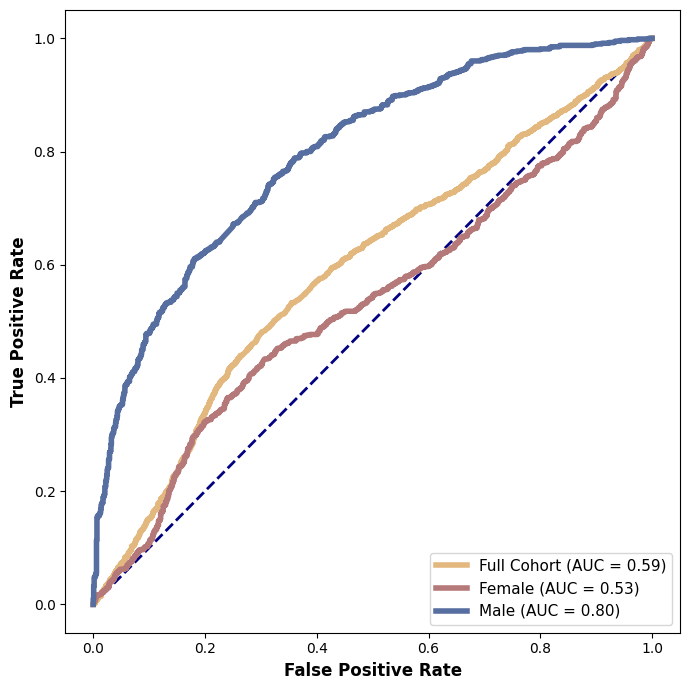

In [9]:
roc_feature_set = 'Comprehensive'
roc_config_label = 'With FS (LR L1)'
roc_groups = ['Full Cohort', 'Female', 'Male']
roc_colors = {'Full Cohort': '#e3b87f', 'Female': '#b57979', 'Male': '#576fa0'}

if all((roc_config_label, roc_feature_set, group) in all_results for group in roc_groups):
    plt.figure(figsize=(7, 7))
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

    for group in roc_groups:
        result = all_results[(roc_config_label, roc_feature_set, group)]
        fpr, tpr, _ = roc_curve(result['y_true'], result['y_pred_prob'])
        roc_auc = auc(fpr, tpr)
        plt.plot(
            fpr,
            tpr,
            lw=4,
            color=roc_colors[group],
            label=f'{group} (AUC = {roc_auc:.2f})',
        )

    plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    plt.legend(loc='lower right', fontsize=11)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f'{RUN_TAG}_Comprehensive_LR_L1_ROC.pdf', bbox_inches='tight')
    plt.show()
else:
    print('Comprehensive LR L1 ROC skipped because not all cohort results are available.')



## 9. LR L1 Feature Tables



In [10]:
def add_selection_frequency(feature_selection_df, n_evaluations):
    out = feature_selection_df.copy()
    if len(out) == 0:
        out['Selection Frequency'] = []
    else:
        out['Selection Frequency'] = out['Total Count'] / n_evaluations
    return out


MAIN_FEATURE_PLOT_TOP_N = 30

feature_panel_outputs = {}
for run_key, tables in feature_outputs.items():
    config_label, feature_set, group = run_key
    if config_label != 'With FS (LR L1)':
        continue

    n_evaluations = len(all_results[run_key]['auc_scores'])
    selection_freq_df = add_feature_display_column(
        add_selection_frequency(tables['feature_selection_df'], n_evaluations)
    )
    coef_df = add_feature_display_column(tables['feature_coef_df'])

    if len(coef_df) > 0:
        fdr_feature_table, fdr_features = utility.filter_significant_features(
            coef_df,
            alpha=0.05,
            use_t=True,
            fdr=True,
            min_count=None,
        )
    else:
        fdr_feature_table = coef_df.copy()
        fdr_features = []

    fdr_feature_table = add_feature_display_column(fdr_feature_table)

    feature_panel_outputs[(feature_set, group)] = {
        'selection_frequency': selection_freq_df,
        'coefficient_summary': coef_df,
        'fdr_feature_table': fdr_feature_table,
        'fdr_features': fdr_features,
    }

    safe_name = f'{RUN_TAG}_LR_L1_{feature_set}_{group}'.replace(' ', '_')
    selection_freq_df.to_csv(RESULT_DIR / f'{safe_name}_selection_frequency.csv', index=False)
    coef_df.to_csv(RESULT_DIR / f'{safe_name}_coefficient_summary.csv', index=False)
    fdr_feature_table.to_csv(RESULT_DIR / f'{safe_name}_fdr_features.csv', index=False)

    print(f'{feature_set} | {group}: {len(fdr_features)} FDR-selected features')

# Compact top-feature tables for manuscript review; full FDR tables are saved above.
top_feature_rows = []
for (feature_set, group), output in feature_panel_outputs.items():
    table = output['fdr_feature_table'].copy()
    if len(table) == 0:
        table = output['coefficient_summary'].nlargest(MAIN_FEATURE_PLOT_TOP_N, 'Abs_Mean_Coefficient').copy()
        table['Feature evidence'] = 'Top coefficient diagnostic'
    else:
        table = table.nlargest(MAIN_FEATURE_PLOT_TOP_N, 'Abs_Mean_Coefficient').copy()
        table['Feature evidence'] = 'FDR coefficient evidence'
    table['Features'] = feature_set
    table['Groups'] = group
    top_feature_rows.append(table)

top_feature_table = pd.concat(top_feature_rows, ignore_index=True) if top_feature_rows else pd.DataFrame()
top_feature_table.to_csv(RESULT_DIR / f'{RUN_TAG}_LR_L1_top{MAIN_FEATURE_PLOT_TOP_N}_feature_table.csv', index=False)
display(top_feature_table.head(40))


Basic | Full Cohort: 3 FDR-selected features
Basic | Female: 3 FDR-selected features
Basic | Male: 3 FDR-selected features
Proteomics | Full Cohort: 154 FDR-selected features
Proteomics | Female: 114 FDR-selected features
Proteomics | Male: 80 FDR-selected features
Metabolomics | Full Cohort: 250 FDR-selected features
Metabolomics | Female: 148 FDR-selected features
Metabolomics | Male: 88 FDR-selected features
Comprehensive | Full Cohort: 69 FDR-selected features
Comprehensive | Female: 64 FDR-selected features
Comprehensive | Male: 75 FDR-selected features


,Feature,Mean_Coefficient,Std_Coefficient,SE_Coefficient,Median_Coefficient,Q1_Coefficient,Q3_Coefficient,Abs_Mean_Coefficient,Count,Feature_Display,p_value,q_value,Feature evidence,Features,Groups
0,Age,0.677812,0.585443,0.119503,0.605771,0.328802,1.091252,0.764668,24,Age,8.953903e-06,1.193854e-05,FDR coefficient evidence,Basic,Full Cohort
1,APOE4,0.518523,0.115334,0.016311,0.497935,0.440730,0.576257,0.518523,50,APOE4,2.280095e-34,9.120380e-34,FDR coefficient evidence,Basic,Full Cohort
2,Demographic.Years of Education Exact,-0.351240,0.240858,0.037165,-0.304571,-0.536953,-0.160095,0.380958,42,Demographic.Years of Education Exact,7.497751e-12,1.499550e-11,FDR coefficient evidence,Basic,Full Cohort
3,APOE4,0.925098,0.166728,0.023579,0.925809,0.829583,1.050133,0.925098,50,APOE4,1.116951e-38,3.350854e-38,FDR coefficient evidence,Basic,Female
4,Age,-0.920637,0.292379,0.041349,-0.882581,-1.024281,-0.726479,0.920637,50,Age,2.801379e-27,4.202068e-27,FDR coefficient evidence,Basic,Female
5,Demographic.Years of Education Exact,0.287367,0.508651,0.085978,0.329738,0.039459,0.640160,0.611226,35,Demographic.Years of Education Exact,2.030472e-03,2.030472e-03,FDR coefficient evidence,Basic,Female
6,Age,2.262773,0.471071,0.066620,2.261959,2.020944,2.498414,2.262773,50,Age,1.022294e-35,3.066883e-35,FDR coefficient evidence,Basic,Male
7,Demographic.Years of Education Exact,-0.822500,0.323167,0.045703,-0.787801,-0.929552,-0.653846,0.891988,50,Demographic.Years of Education Exact,3.091740e-23,3.091740e-23,FDR coefficient evidence,Basic,Male
8,APOE4,0.772070,0.180307,0.025499,0.749176,0.664021,0.858160,0.773785,50,APOE4,2.218007e-33,3.327011e-33,FDR coefficient evidence,Basic,Male
9,PRDX6,-3.628403,2.916958,0.507777,-2.782399,-4.610617,-1.788561,3.628403,33,PRDX6,4.130778e-08,8.771829e-07,FDR coefficient evidence,Proteomics,Full Cohort


## 10. Essential Feature Plots



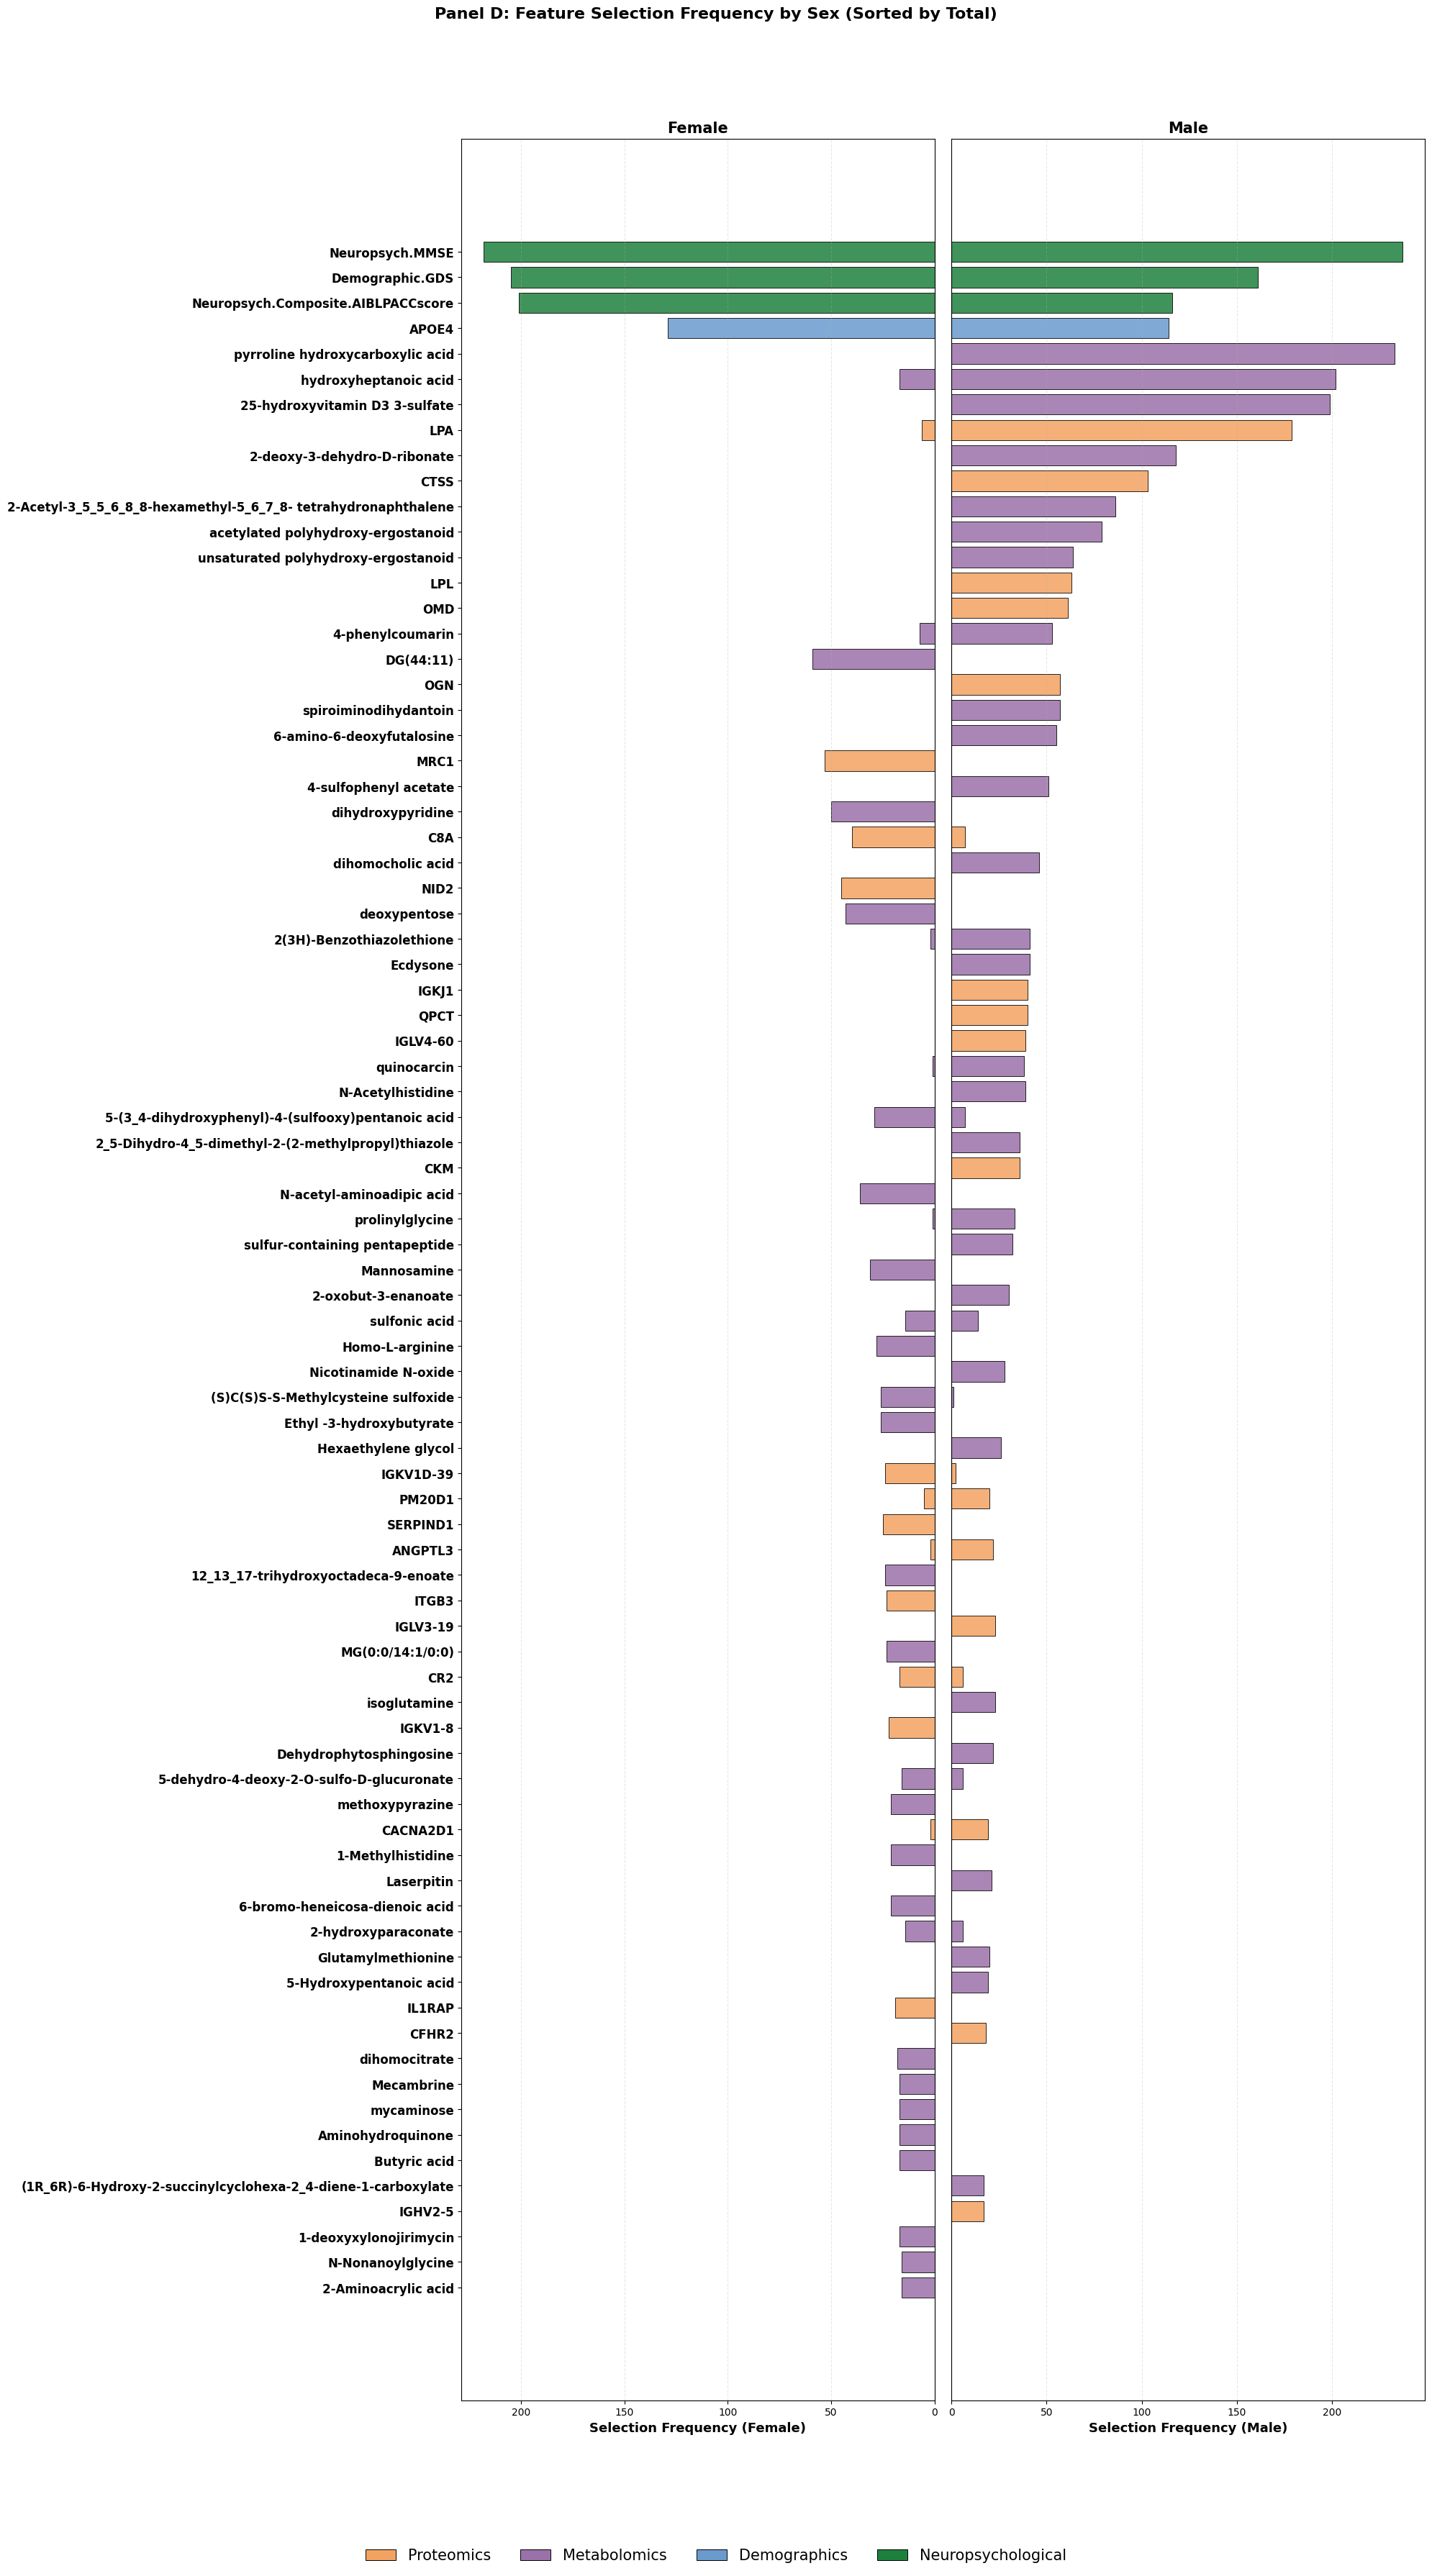

Plot saved to ../plots/minmax_outer5_inner5_50run_LR_L1_Comprehensive_Female_feature_coefficients.pdf


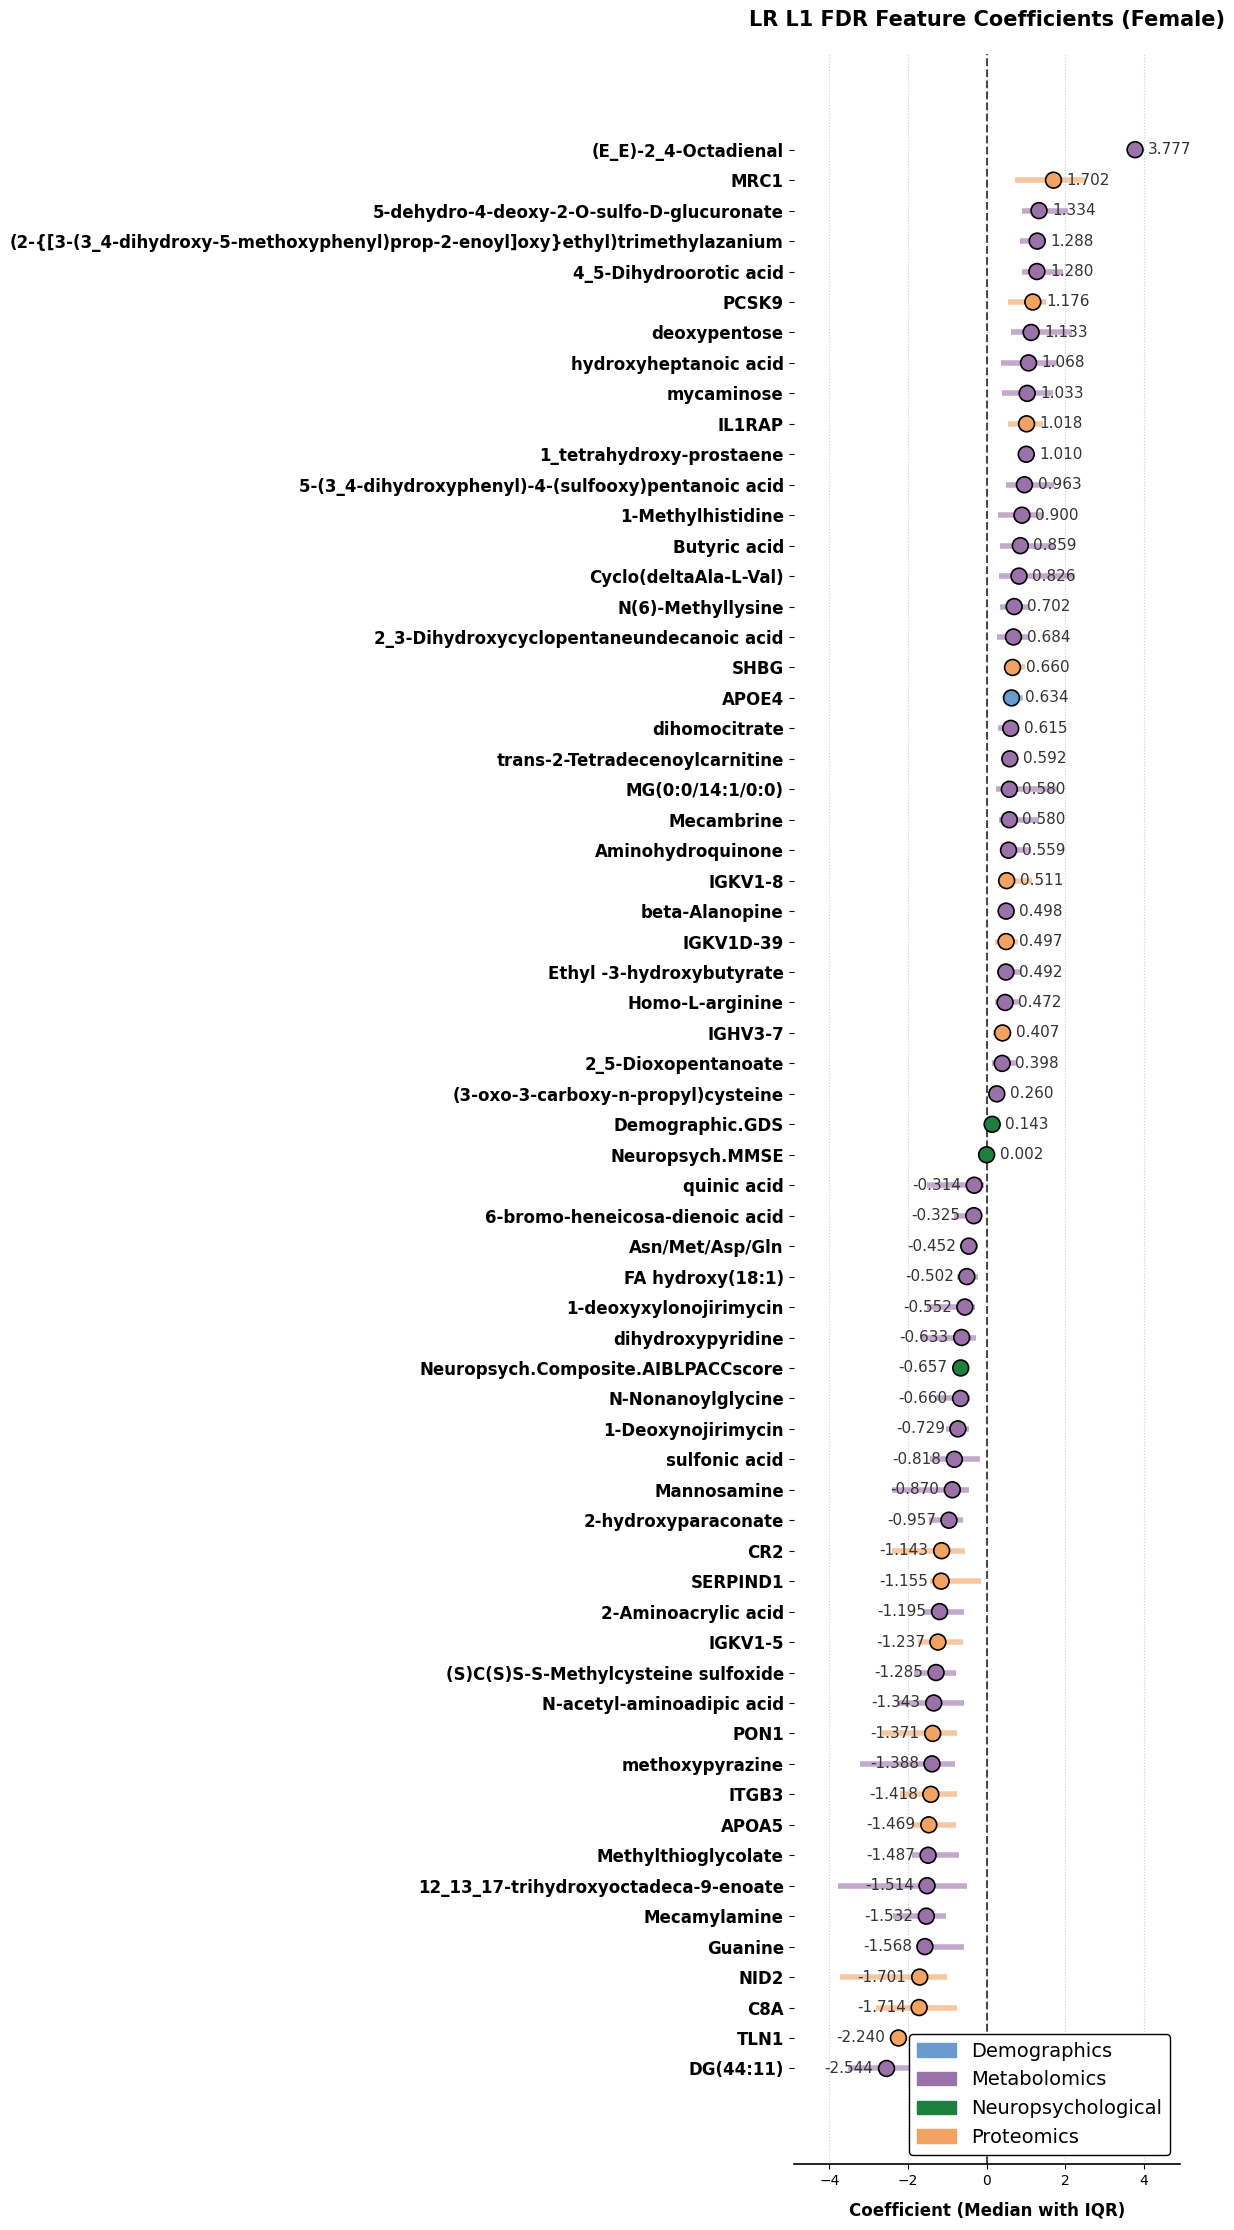

Plot saved to ../plots/minmax_outer5_inner5_50run_LR_L1_Comprehensive_Male_feature_coefficients.pdf


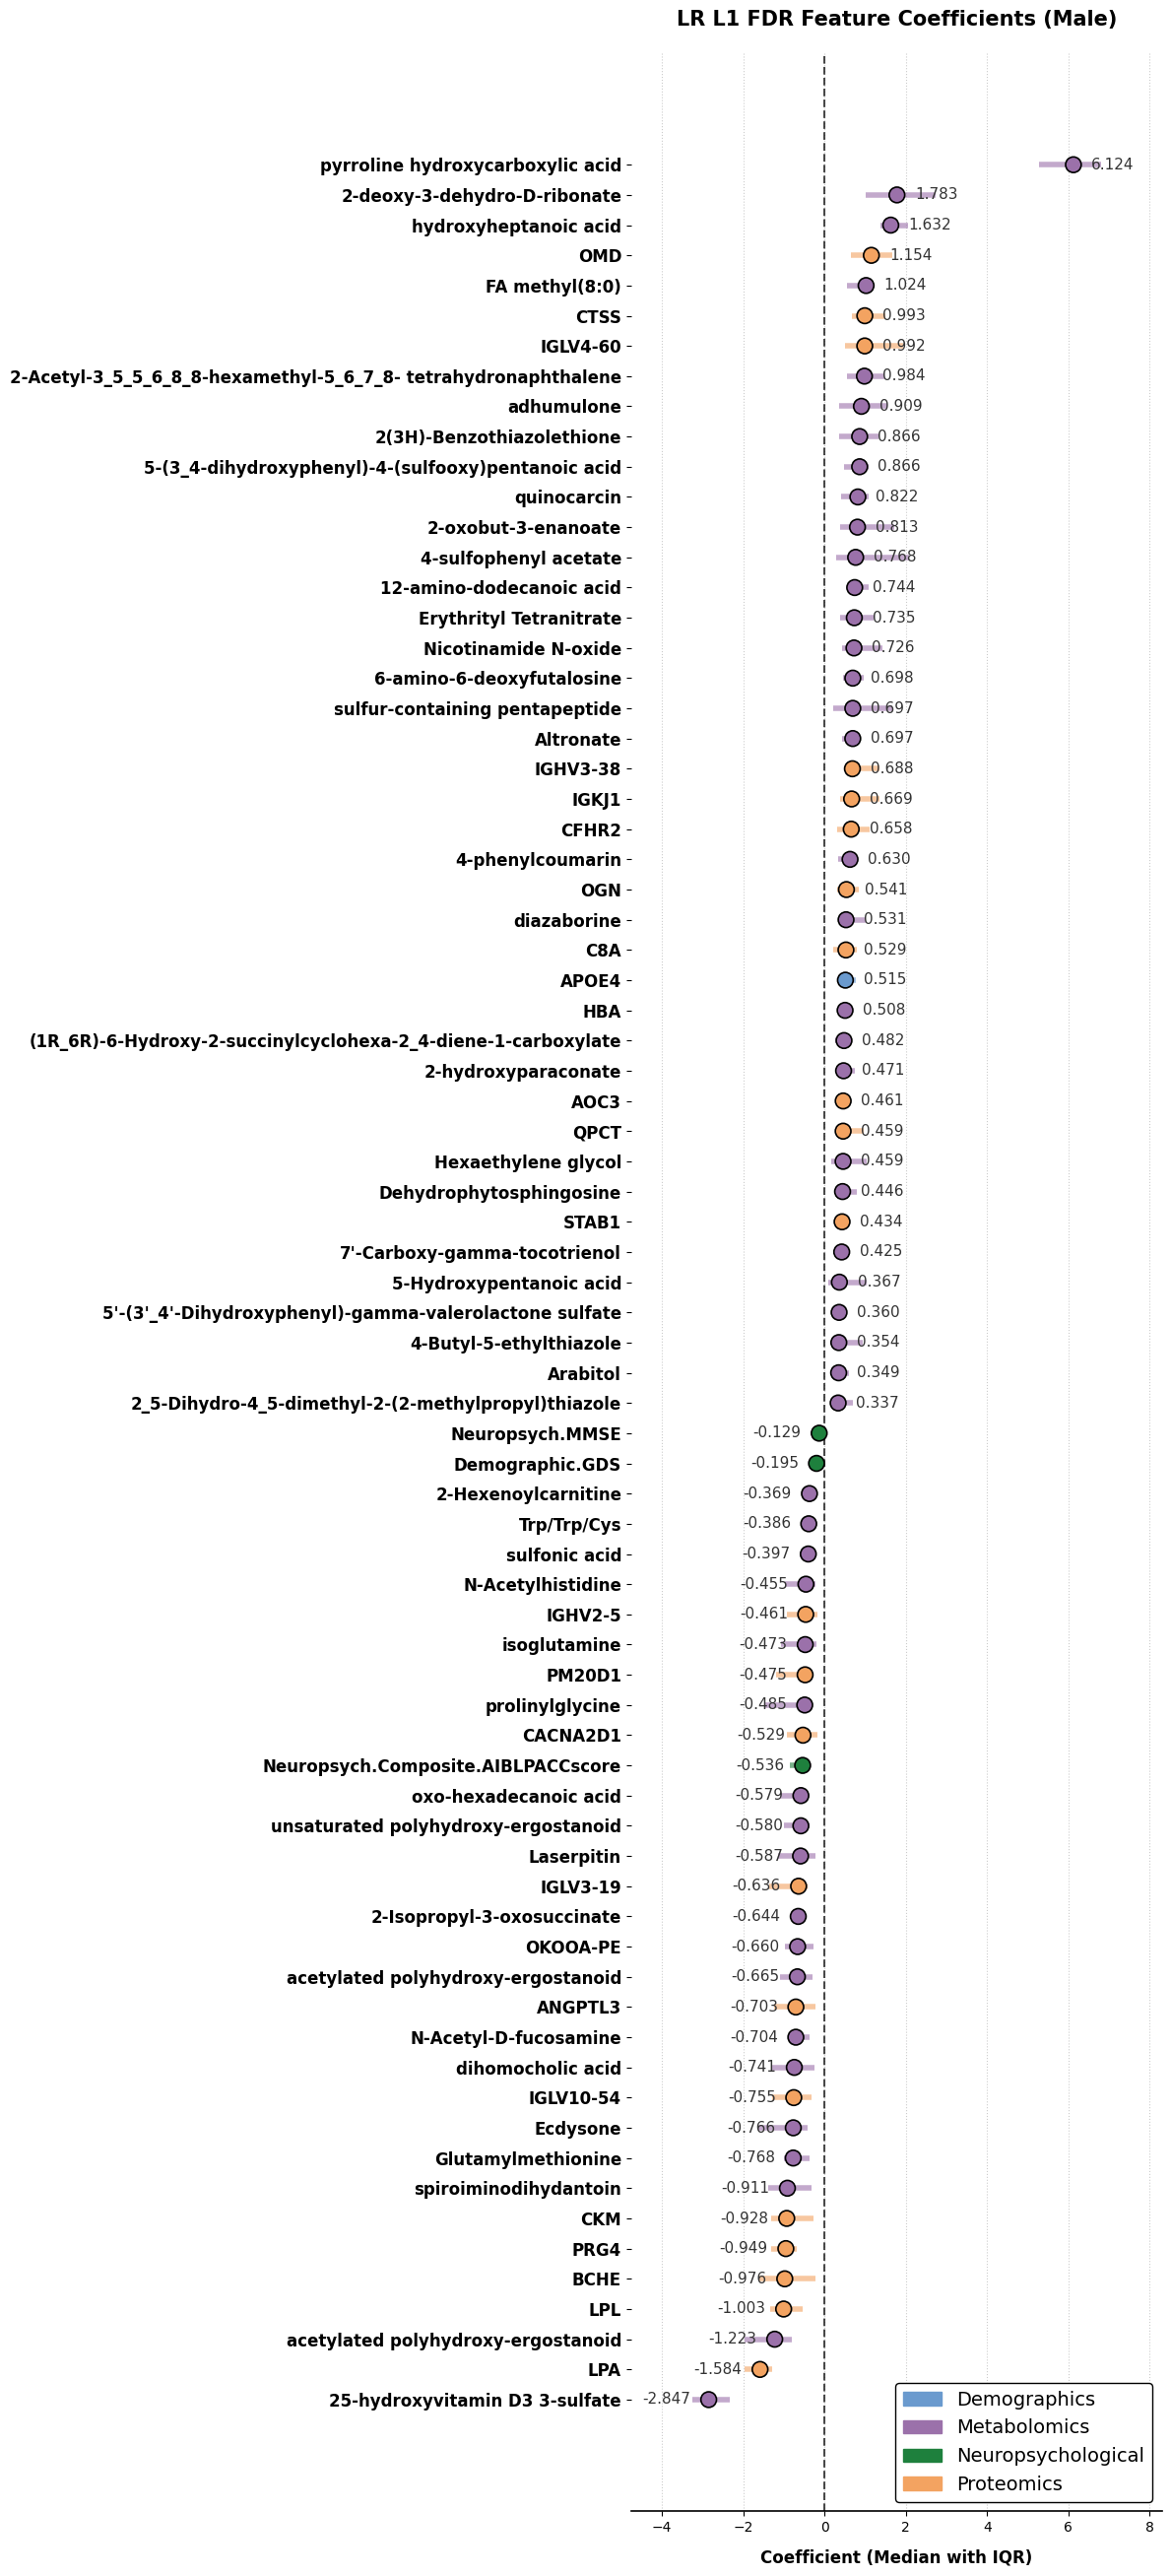

In [11]:
# Female/Male comprehensive LR L1 feature plots.
run_key_f = ('Comprehensive', 'Female')
run_key_m = ('Comprehensive', 'Male')
MAIN_FEATURE_PLOT_TOP_N = 30

plot_type_cols = {
    'demographic_cols': manuscript_feature_list(demographic_cols),
    'proteomic_cols': manuscript_feature_list(proteomic_cols),
    'metabolomics_cols': manuscript_feature_list(metabolomics_cols),
    'neuropsychological_cols': manuscript_feature_list(neuropsychological_cols),
}


def filter_frequency_to_fdr(selection_df, fdr_features):
    out = selection_df[selection_df['Feature'].isin(set(fdr_features))].copy()
    return out.sort_values(['Total Count', 'Selection Frequency'], ascending=False)


if run_key_f in feature_panel_outputs and run_key_m in feature_panel_outputs:
    fs_f_fdr = filter_frequency_to_fdr(
        feature_panel_outputs[run_key_f]['selection_frequency'],
        feature_panel_outputs[run_key_f]['fdr_features'],
    )
    fs_m_fdr = filter_frequency_to_fdr(
        feature_panel_outputs[run_key_m]['selection_frequency'],
        feature_panel_outputs[run_key_m]['fdr_features'],
    )

    if len(fs_f_fdr) == 0 and len(fs_m_fdr) == 0:
        fs_f_fdr = feature_panel_outputs[run_key_f]['selection_frequency'].copy()
        fs_m_fdr = feature_panel_outputs[run_key_m]['selection_frequency'].copy()
        print('No FDR-selected feature union; plotting top selected features as a diagnostic.')

    fs_f_plot_display = use_feature_display_for_plot(fs_f_fdr)
    fs_m_plot_display = use_feature_display_for_plot(fs_m_fdr)

    # Main Figure 4A-style frequency plot: top 30 FDR-supported selected features.
    utility.plot_panel_d_butterfly_enhanced(
        feature_selection_df_M=fs_m_plot_display,
        feature_selection_df_F=fs_f_plot_display,
        **plot_type_cols,
        top_n=MAIN_FEATURE_PLOT_TOP_N,
        save_path=PLOT_DIR / f'{RUN_TAG}_LR_L1_Comprehensive_feature_selection_butterfly_top{MAIN_FEATURE_PLOT_TOP_N}.pdf',
        figsize=(18, 10),
        label_font_size=10,
    )

    # Supplementary version: full FDR-supported selection-frequency plot.
    full_freq_top_n = max(len(fs_f_plot_display), len(fs_m_plot_display), 1)
    utility.plot_panel_d_butterfly_enhanced(
        feature_selection_df_M=fs_m_plot_display,
        feature_selection_df_F=fs_f_plot_display,
        **plot_type_cols,
        top_n=full_freq_top_n,
        save_path=PLOT_DIR / f'{RUN_TAG}_LR_L1_Comprehensive_feature_selection_butterfly_full_FDR.pdf',
        figsize=(20, max(8, 0.45 * full_freq_top_n)),
        label_font_size=8,
    )
else:
    print('Butterfly plot skipped because Comprehensive Female/Male LR L1 outputs are unavailable.')

# Female/Male comprehensive coefficient lollipop plots.
for group in ['Female', 'Male']:
    run_key = ('Comprehensive', group)
    if run_key not in feature_panel_outputs:
        continue

    fdr_df = feature_panel_outputs[run_key]['fdr_feature_table'].copy()
    coef_df = feature_panel_outputs[run_key]['coefficient_summary'].copy()

    if len(fdr_df) > 0:
        plot_df = use_feature_display_for_plot(fdr_df)
        plot_source_label = 'FDR Feature Coefficients'
    else:
        plot_df = use_feature_display_for_plot(coef_df)
        plot_source_label = 'Top Coefficients Diagnostic'

    if len(plot_df) == 0:
        print(f'No coefficient rows available for {group}.')
        continue

    # Main Figure 4B/C-style coefficient plot: top 30 strongest coefficients.
    main_top_n = min(MAIN_FEATURE_PLOT_TOP_N, len(plot_df))
    utility.plot_feature_coefficients_lollipop_enhanced(
        plot_df,
        **plot_type_cols,
        top_n=main_top_n,
        save_path=PLOT_DIR / f'{RUN_TAG}_LR_L1_Comprehensive_{group}_feature_coefficients_top{MAIN_FEATURE_PLOT_TOP_N}.pdf',
        figsize=(12, max(6, 0.35 * main_top_n)),
        title=f'LR L1 {plot_source_label}: Top {main_top_n} ({group})',
    )

    # Supplementary version: full FDR-supported coefficient plot.
    full_coef_top_n = len(plot_df)
    utility.plot_feature_coefficients_lollipop_enhanced(
        plot_df,
        **plot_type_cols,
        top_n=full_coef_top_n,
        save_path=PLOT_DIR / f'{RUN_TAG}_LR_L1_Comprehensive_{group}_feature_coefficients_full_FDR.pdf',
        figsize=(12, max(6, 0.35 * full_coef_top_n)),
        title=f'LR L1 {plot_source_label}: Full FDR List ({group})',
    )


## 11. Short Result Text



In [12]:
if 'With FS - Without FS' in auc_wide.columns:
    comp_gain = auc_wide[auc_wide['Features'].eq('Comprehensive')].copy()
    display(comp_gain)

print(
    'Primary analysis used MinMax scaling, 50 repeated nested CV runs, '
    '5 outer folds, and 5 inner folds. LR L1 represents embedded feature selection; '
    'LR L2 is the no-embedded-feature-selection comparator. Use the formatted AUC table '
    f'at ../results/{RUN_TAG}_auc_table_formatted.csv for manuscript values.'
)



Feature Selection,Groups,Features,With FS,Without FS,With FS - Without FS
1,Female,Comprehensive,0.583333,0.625000,-0.041667
5,Full Cohort,Comprehensive,0.610390,0.519481,0.090909
9,Male,Comprehensive,0.866667,0.400000,0.466667


Primary analysis used MinMax scaling, 50 repeated nested CV runs, 5 outer folds, and 5 inner folds. LR L1 represents embedded feature selection; LR L2 is the no-embedded-feature-selection comparator. Use the formatted AUC table at ../results/minmax_outer5_inner5_50run_auc_table_formatted.csv for manuscript values.


## 10. Overlap of PLS-DA, Volcano, and LR L1 Feature Selection

This section uses the existing Figure 2 outputs and LR L1 FDR feature-selection outputs to identify candidate features supported by multiple analytical layers. S-plot features are intentionally excluded. The first table keeps features overlapping between PLS-DA VIP > 1 and volcano/differential abundance p < 0.05. The second table intersects that set with LR L1-selected features separately for proteomics, metabolomics, and comprehensive models.


In [13]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

RESULT_DIR = Path('../results')
RUN_TAG = globals().get('RUN_TAG', 'minmax_outer5_inner5_50run')

# Overlap features across Figure 2 descriptive analyses and LR L1 feature selection.
# Inputs expected from Figure2v2.Rmd:
#   ../results/plsda_features_female_selected.csv
#   ../results/plsda_features_male_selected.csv
#   ../results/DE_results_Female.csv
#   ../results/DE_results_Male.csv
# Inputs expected from this notebook:
#   ../results/{RUN_TAG}_LR_L1_{Proteomics/Metabolomics/Comprehensive}_{Female/Male}_fdr_features.csv
#   ../results/{RUN_TAG}_LR_L1_{Proteomics/Metabolomics/Comprehensive}_{Female/Male}_selection_frequency.csv

OVERLAP_PLSDA_VIP_CUTOFF = 1.0
OVERLAP_VOLCANO_P_CUTOFF = 0.05
OVERLAP_LR_L1_Q_CUTOFF = 0.05
OVERLAP_GROUPS = ['Female', 'Male']
OVERLAP_LR_L1_FEATURE_SETS = ['Proteomics', 'Metabolomics', 'Comprehensive']


OVERLAP_MANUSCRIPT_FEATURE_NAME_MAP = globals().get('MANUSCRIPT_FEATURE_NAME_MAP', {
    '2_5-Dihydroxypyridine': 'dihydroxypyridine',
    '2,5-Dihydroxypyridine': 'dihydroxypyridine',
    '6beta-acetoxy-24-methylcholestan-3beta_5alpha_22R_24-tetrol': 'acetylated polyhydroxy-ergostanoid',
    '6beta-acetoxy-24-methylcholestan-3beta,5alpha,22R,24-tetrol': 'acetylated polyhydroxy-ergostanoid',
    '7beta-acetoxy-gorgostan-3beta_5alpha_6beta-triol': 'acetylated polyhydroxy-ergostanoid',
    "6-Butyryl-5_7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin": '4-phenylcoumarin',
    "6-Butyryl-5,7-dihydroxy-8-(3'_3'-dimethylallyl)-4-phenylcoumarin": '4-phenylcoumarin',
    'Aminoadipic acid': 'aminoadipic acid',
    'cyclopentanehexanoic acid': 'oxo-hexadecanoic acid',
    'Cyclopentanehexanoic acid': 'oxo-hexadecanoic acid',
    'Cys/Asp/Asp/Thr/Thr': 'sulfur-containing pentapeptide',
    'DG(22:5/22:6/0:0)': 'DG(44:11)',
    'Dihomocholic acid': 'dihomocholic acid',
    'epithio-seco-cholestadienetriol S_S-dioxide': '25-hydroxyvitamin D3 3-sulfate',
    'Epithio-seco-cholestadienetriol S,S-dioxide': '25-hydroxyvitamin D3 3-sulfate',
    'FA hydroxy(7:0)': 'hydroxyheptanoic acid',
    'Methylimidazole acetaldehyde (MIA)': 'methylimidazole acetaldehyde (MIA)',
    'N-acetyl-L-2-aminoadipate(2-)': 'N-acetyl-aminoadipic acid',
    'Pyrroline hydroxycarboxylic acid': 'pyrroline hydroxycarboxylic acid',
    'Stoloniferone F': 'unsaturated polyhydroxy-ergostanoid',
    'Sulfonic acid': 'sulfonic acid',
    '{[-3-phenylprop-2-en-1-yl]oxy}sulfonic acid': 'sulfonic acid',
    '3-Isopropyl-2-methoxy-5-methylpyrazine': 'methoxypyrazine',
    'Quinic acid': 'quinic acid',
    'Deoxyribose': 'deoxypentose',
    'Guanosine': 'guanosine',
})


def overlap_manuscript_feature_name(value):
    if pd.isna(value):
        return value
    clean_name = overlap_clean_feature_name(value)
    return OVERLAP_MANUSCRIPT_FEATURE_NAME_MAP.get(clean_name, clean_name)


def add_overlap_feature_display(df, key_col='Feature_clean'):
    out = df.copy()
    if key_col in out.columns:
        out['Feature_Manuscript'] = out[key_col].map(overlap_manuscript_feature_name)
    return out


def overlap_clean_feature_name(value):
    if pd.isna(value):
        return value
    return re.sub(r'\.\d$', '', str(value))


def overlap_volcano_direction(significance):
    if significance == 'Up':
        return 'Higher in Amyloid+'
    if significance == 'Down':
        return 'Higher in Amyloid-'
    return 'Not selected'


def overlap_lr_l1_direction(coef):
    if pd.isna(coef):
        return np.nan
    if coef > 0:
        return 'Increased predicted Amyloid+ risk'
    if coef < 0:
        return 'Decreased predicted Amyloid+ risk'
    return 'Neutral'


def overlap_direction_agreement(logfc, coef):
    if pd.isna(logfc) or pd.isna(coef) or logfc == 0 or coef == 0:
        return np.nan
    return 'Concordant' if np.sign(logfc) == np.sign(coef) else 'Discordant'


def load_overlap_plsda(group):
    path = RESULT_DIR / f'plsda_features_{group.lower()}_selected.csv'
    df = pd.read_csv(path)
    df['Feature_clean'] = df['Feature'].map(overlap_clean_feature_name)
    df = df[df['VIP_Score'] > OVERLAP_PLSDA_VIP_CUTOFF].copy()
    return df.rename(columns={
        'Feature': 'PLSDA_Feature',
        'VIP_Score': 'PLSDA_VIP',
        'Loading_Comp1': 'PLSDA_Loading_Comp1',
        'Direction': 'PLSDA_Direction',
        'Omics_Type': 'PLSDA_Omics_Type',
    })


def load_overlap_volcano(group):
    path = RESULT_DIR / f'DE_results_{group}.csv'
    df = pd.read_csv(path)
    df['Feature_clean'] = df['Feature'].map(overlap_clean_feature_name)
    df['Volcano_Direction'] = df['Significance'].map(overlap_volcano_direction)
    df = df[(df['P_Value'] < OVERLAP_VOLCANO_P_CUTOFF) & df['Significance'].isin(['Up', 'Down'])].copy()
    return df.rename(columns={
        'Feature': 'Volcano_Feature',
        'logFC': 'Volcano_logFC',
        'P_Value': 'Volcano_P_Value',
        'logP': 'Volcano_neglog10P',
        'Significance': 'Volcano_Significance',
        'Omics_Type': 'Volcano_Omics_Type',
    })


def load_overlap_lr_l1(group, feature_set):
    fdr_path = RESULT_DIR / f'{RUN_TAG}_LR_L1_{feature_set}_{group}_fdr_features.csv'
    freq_path = RESULT_DIR / f'{RUN_TAG}_LR_L1_{feature_set}_{group}_selection_frequency.csv'

    if not fdr_path.exists():
        print(f'Missing LR L1 FDR file: {fdr_path}')
        return pd.DataFrame()

    fdr_df = pd.read_csv(fdr_path)
    if fdr_df.empty:
        return pd.DataFrame()

    fdr_df['Feature_clean'] = fdr_df['Feature'].map(overlap_clean_feature_name)
    if 'q_value' in fdr_df.columns:
        fdr_df = fdr_df[fdr_df['q_value'] < OVERLAP_LR_L1_Q_CUTOFF].copy()
    if fdr_df.empty:
        return pd.DataFrame()

    freq_cols = ['Feature_clean', 'LR_L1_Total_Count', 'LR_L1_Selection_Frequency']
    if freq_path.exists():
        freq_df = pd.read_csv(freq_path)
        freq_df['Feature_clean'] = freq_df['Feature'].map(overlap_clean_feature_name)
        freq_df = freq_df.rename(columns={
            'Total Count': 'LR_L1_Total_Count',
            'Selection Frequency': 'LR_L1_Selection_Frequency',
        })
        freq_df = freq_df[[c for c in freq_cols if c in freq_df.columns]].drop_duplicates('Feature_clean')
        fdr_df = fdr_df.merge(freq_df, on='Feature_clean', how='left')

    fdr_df['Group'] = group
    fdr_df['LR_L1_Model_Feature_Set'] = feature_set
    fdr_df['LR_L1_Direction'] = fdr_df['Median_Coefficient'].map(overlap_lr_l1_direction)

    rename_map = {
        'Feature': 'LR_L1_Feature',
        'Median_Coefficient': 'LR_L1_Median_Coefficient',
        'Q1_Coefficient': 'LR_L1_Q1_Coefficient',
        'Q3_Coefficient': 'LR_L1_Q3_Coefficient',
        'Mean_Coefficient': 'LR_L1_Mean_Coefficient',
        'Abs_Mean_Coefficient': 'LR_L1_Abs_Mean_Coefficient',
        'Count': 'LR_L1_Coefficient_Count',
        'p_value': 'LR_L1_p_value',
        'q_value': 'LR_L1_q_value',
    }
    fdr_df = fdr_df.rename(columns=rename_map)

    keep_cols = [
        'Group', 'Feature_clean', 'LR_L1_Feature', 'LR_L1_Model_Feature_Set',
        'LR_L1_Median_Coefficient', 'LR_L1_Q1_Coefficient', 'LR_L1_Q3_Coefficient',
        'LR_L1_Mean_Coefficient', 'LR_L1_Abs_Mean_Coefficient',
        'LR_L1_Coefficient_Count', 'LR_L1_Total_Count', 'LR_L1_Selection_Frequency',
        'LR_L1_p_value', 'LR_L1_q_value', 'LR_L1_Direction',
    ]
    return fdr_df[[c for c in keep_cols if c in fdr_df.columns]].copy()


plsda_volcano_tables = []
lr_l1_tables = []

for group in OVERLAP_GROUPS:
    plsda_df = load_overlap_plsda(group)
    volcano_df = load_overlap_volcano(group)

    base_overlap = plsda_df.merge(volcano_df, on='Feature_clean', how='inner')
    base_overlap['Group'] = group
    plsda_volcano_tables.append(base_overlap)

    for feature_set in OVERLAP_LR_L1_FEATURE_SETS:
        lr_df = load_overlap_lr_l1(group, feature_set)
        if lr_df.empty:
            continue

        overlap_df = base_overlap.merge(
            lr_df.drop(columns=['Group'], errors='ignore'),
            on='Feature_clean',
            how='inner',
        )
        overlap_df['Group'] = group
        overlap_df['LR_L1_Model_Feature_Set'] = feature_set
        overlap_df['Volcano_LR_L1_Direction_Agreement'] = overlap_df.apply(
            lambda row: overlap_direction_agreement(row.get('Volcano_logFC'), row.get('LR_L1_Median_Coefficient')),
            axis=1,
        )
        lr_l1_tables.append(overlap_df)

plsda_volcano_overlap_df = pd.concat(plsda_volcano_tables, ignore_index=True) if plsda_volcano_tables else pd.DataFrame()
plsda_volcano_lr_l1_overlap_df = pd.concat(lr_l1_tables, ignore_index=True) if lr_l1_tables else pd.DataFrame()
plsda_volcano_overlap_df = add_overlap_feature_display(plsda_volcano_overlap_df)
plsda_volcano_lr_l1_overlap_df = add_overlap_feature_display(plsda_volcano_lr_l1_overlap_df)

base_cols = [
    'Group', 'Feature_Manuscript', 'Feature_clean',
    'PLSDA_Feature', 'PLSDA_Omics_Type', 'PLSDA_VIP', 'PLSDA_Loading_Comp1', 'PLSDA_Direction',
    'Volcano_Feature', 'Volcano_Omics_Type', 'Volcano_logFC', 'Volcano_P_Value', 'Volcano_neglog10P',
    'Volcano_Significance', 'Volcano_Direction',
]
base_cols = [c for c in base_cols if c in plsda_volcano_overlap_df.columns]
plsda_volcano_overlap_df = plsda_volcano_overlap_df[base_cols].sort_values(
    ['Group', 'Volcano_P_Value', 'Feature_clean'],
    ascending=[True, True, True],
)

l1_cols = base_cols + [
    'LR_L1_Model_Feature_Set', 'LR_L1_Feature',
    'LR_L1_Median_Coefficient', 'LR_L1_Q1_Coefficient', 'LR_L1_Q3_Coefficient',
    'LR_L1_Mean_Coefficient', 'LR_L1_Abs_Mean_Coefficient',
    'LR_L1_Coefficient_Count', 'LR_L1_Total_Count', 'LR_L1_Selection_Frequency',
    'LR_L1_p_value', 'LR_L1_q_value', 'LR_L1_Direction',
    'Volcano_LR_L1_Direction_Agreement',
]
l1_cols = [c for c in l1_cols if c in plsda_volcano_lr_l1_overlap_df.columns]
plsda_volcano_lr_l1_overlap_df = plsda_volcano_lr_l1_overlap_df[l1_cols].sort_values(
    ['Group', 'LR_L1_Model_Feature_Set', 'Volcano_P_Value', 'Feature_clean'],
    ascending=[True, True, True, True],
)

# Collapsed version: one row per sex-feature, showing which LR L1 model(s) selected it.
if not plsda_volcano_lr_l1_overlap_df.empty:
    representative = (
        plsda_volcano_lr_l1_overlap_df
        .sort_values(['Group', 'Feature_clean', 'LR_L1_q_value', 'LR_L1_Abs_Mean_Coefficient'], ascending=[True, True, True, False])
        .groupby(['Group', 'Feature_clean'], as_index=False)
        .first()
    )

    selected_in = (
        plsda_volcano_lr_l1_overlap_df
        .groupby(['Group', 'Feature_clean'])
        .agg(
            LR_L1_Selected_In=('LR_L1_Model_Feature_Set', lambda x: '; '.join(sorted(set(x)))),
            LR_L1_Selected_In_N=('LR_L1_Model_Feature_Set', lambda x: len(set(x))),
        )
        .reset_index()
    )

    plsda_volcano_lr_l1_collapsed_df = representative.merge(
        selected_in,
        on=['Group', 'Feature_clean'],
        how='left',
    )

    collapsed_cols = [
        'Group', 'Feature_clean', 'PLSDA_Omics_Type', 'Volcano_Omics_Type',
        'PLSDA_VIP', 'PLSDA_Direction', 'Volcano_logFC', 'Volcano_P_Value', 'Volcano_Direction',
        'LR_L1_Selected_In', 'LR_L1_Selected_In_N', 'LR_L1_Model_Feature_Set',
        'LR_L1_Median_Coefficient', 'LR_L1_Q1_Coefficient', 'LR_L1_Q3_Coefficient',
        'LR_L1_Selection_Frequency', 'LR_L1_q_value', 'LR_L1_Direction',
        'Volcano_LR_L1_Direction_Agreement',
    ]
    collapsed_cols = [c for c in collapsed_cols if c in plsda_volcano_lr_l1_collapsed_df.columns]
    plsda_volcano_lr_l1_collapsed_df = plsda_volcano_lr_l1_collapsed_df[collapsed_cols].sort_values(
        ['Group', 'LR_L1_Selected_In_N', 'Volcano_P_Value', 'Feature_clean'],
        ascending=[True, False, True, True],
    )
else:
    plsda_volcano_lr_l1_collapsed_df = pd.DataFrame()

summary_rows = []
for group in OVERLAP_GROUPS:
    group_base = plsda_volcano_overlap_df[plsda_volcano_overlap_df['Group'].eq(group)]
    summary_rows.append({
        'Group': group,
        'LR_L1_Model_Feature_Set': 'PLSDA + volcano only',
        'Overlap_N': len(group_base),
        'Metabolomics_N': int((group_base.get('Volcano_Omics_Type', pd.Series(dtype=str)) == 'Metabolomics').sum()),
        'Proteomics_N': int((group_base.get('Volcano_Omics_Type', pd.Series(dtype=str)) == 'Proteomics').sum()),
    })

    for feature_set in OVERLAP_LR_L1_FEATURE_SETS:
        group_l1 = plsda_volcano_lr_l1_overlap_df[
            plsda_volcano_lr_l1_overlap_df['Group'].eq(group)
            & plsda_volcano_lr_l1_overlap_df['LR_L1_Model_Feature_Set'].eq(feature_set)
        ]
        summary_rows.append({
            'Group': group,
            'LR_L1_Model_Feature_Set': feature_set,
            'Overlap_N': len(group_l1),
            'Metabolomics_N': int((group_l1.get('Volcano_Omics_Type', pd.Series(dtype=str)) == 'Metabolomics').sum()),
            'Proteomics_N': int((group_l1.get('Volcano_Omics_Type', pd.Series(dtype=str)) == 'Proteomics').sum()),
        })

overlap_summary_df = pd.DataFrame(summary_rows)

# Main-manuscript Table 3: strict final panel from the Comprehensive LR L1 model only.
comprehensive_overlap_df = plsda_volcano_lr_l1_overlap_df[
    plsda_volcano_lr_l1_overlap_df['LR_L1_Model_Feature_Set'].eq('Comprehensive')
].copy()

if not comprehensive_overlap_df.empty:
    comprehensive_overlap_df['Sex'] = comprehensive_overlap_df['Group']
    comprehensive_overlap_df['Feature name'] = comprehensive_overlap_df['Feature_Manuscript']
    comprehensive_overlap_df['Original feature ID'] = comprehensive_overlap_df['Feature_clean']
    comprehensive_overlap_df['Omics type'] = comprehensive_overlap_df['Volcano_Omics_Type']
    comprehensive_overlap_df['Direction in Aβ+'] = comprehensive_overlap_df['Volcano_Direction'].map({
        'Higher in Amyloid+': 'Higher in Aβ+',
        'Higher in Amyloid-': 'Lower in Aβ+',
    }).fillna(comprehensive_overlap_df['Volcano_Direction'])
    comprehensive_overlap_df['ML risk direction'] = comprehensive_overlap_df['LR_L1_Direction'].map({
        'Increased predicted Amyloid+ risk': 'Increased predicted Aβ+ risk',
        'Decreased predicted Amyloid+ risk': 'Decreased predicted Aβ+ risk',
    }).fillna(comprehensive_overlap_df['LR_L1_Direction'])
    comprehensive_overlap_df['LR L1 beta, median [Q1, Q3]'] = comprehensive_overlap_df.apply(
        lambda row: f"{row['LR_L1_Median_Coefficient']:.3f} [{row['LR_L1_Q1_Coefficient']:.3f}, {row['LR_L1_Q3_Coefficient']:.3f}]",
        axis=1,
    )
    comprehensive_overlap_df['Selection frequency'] = comprehensive_overlap_df['LR_L1_Selection_Frequency'].map(
        lambda x: f'{x:.3f}' if pd.notna(x) else np.nan
    )
    comprehensive_overlap_df['PLS-DA VIP'] = comprehensive_overlap_df['PLSDA_VIP'].map(lambda x: f'{x:.3f}')
    comprehensive_overlap_df['Volcano p value'] = comprehensive_overlap_df['Volcano_P_Value'].map(lambda x: f'{x:.4g}')
    comprehensive_overlap_df['LR L1 FDR q value'] = comprehensive_overlap_df['LR_L1_q_value'].map(lambda x: f'{x:.4g}')

    comprehensive_overlap_df['_sex_order'] = comprehensive_overlap_df['Sex'].map({'Female': 0, 'Male': 1})
    comprehensive_overlap_df['_omics_order'] = comprehensive_overlap_df['Omics type'].map({'Metabolomics': 0, 'Proteomics': 1})
    comprehensive_overlap_df = comprehensive_overlap_df.sort_values(
        ['_sex_order', '_omics_order', 'Volcano_P_Value', 'Feature name'],
        ascending=[True, True, True, True],
    )

    table3_candidate_panel = comprehensive_overlap_df[[
        'Sex', 'Feature name', 'Original feature ID', 'Omics type',
        'Direction in Aβ+', 'ML risk direction',
        'PLS-DA VIP', 'Volcano p value',
        'LR L1 beta, median [Q1, Q3]', 'Selection frequency', 'LR L1 FDR q value',
    ]].copy()
else:
    table3_candidate_panel = pd.DataFrame(columns=[
        'Sex', 'Feature name', 'Original feature ID', 'Omics type',
        'Direction in Aβ+', 'ML risk direction',
        'PLS-DA VIP', 'Volcano p value',
        'LR L1 beta, median [Q1, Q3]', 'Selection frequency', 'LR L1 FDR q value',
    ])

# Save outputs for manuscript and supplementary checks.
base_csv = RESULT_DIR / f'{RUN_TAG}_PLSDA_volcano_overlap.csv'
l1_long_csv = RESULT_DIR / f'{RUN_TAG}_PLSDA_volcano_LR_L1_overlap_by_model.csv'
l1_collapsed_csv = RESULT_DIR / f'{RUN_TAG}_PLSDA_volcano_LR_L1_overlap_collapsed.csv'
summary_csv = RESULT_DIR / f'{RUN_TAG}_PLSDA_volcano_LR_L1_overlap_summary.csv'
table3_csv = RESULT_DIR / f'{RUN_TAG}_Table3_final_candidate_biomarker_panel.csv'
table3_md = RESULT_DIR / f'{RUN_TAG}_Table3_final_candidate_biomarker_panel.md'
excel_path = RESULT_DIR / f'{RUN_TAG}_PLSDA_volcano_LR_L1_overlap.xlsx'

plsda_volcano_overlap_df.to_csv(base_csv, index=False)
plsda_volcano_lr_l1_overlap_df.to_csv(l1_long_csv, index=False)
plsda_volcano_lr_l1_collapsed_df.to_csv(l1_collapsed_csv, index=False)
overlap_summary_df.to_csv(summary_csv, index=False)
table3_candidate_panel.to_csv(table3_csv, index=False)

markdown_lines = [
    '| ' + ' | '.join(table3_candidate_panel.columns) + ' |',
    '| ' + ' | '.join(['---'] * len(table3_candidate_panel.columns)) + ' |',
]
for _, row in table3_candidate_panel.iterrows():
    markdown_lines.append('| ' + ' | '.join(str(row[col]).replace('|', '/') for col in table3_candidate_panel.columns) + ' |')
table3_md.write_text('\n'.join(markdown_lines))

try:
    with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
        overlap_summary_df.to_excel(writer, sheet_name='summary', index=False)
        plsda_volcano_overlap_df.to_excel(writer, sheet_name='PLSDA_volcano', index=False)
        plsda_volcano_lr_l1_overlap_df.to_excel(writer, sheet_name='PLSDA_volcano_LR_L1_long', index=False)
        plsda_volcano_lr_l1_collapsed_df.to_excel(writer, sheet_name='PLSDA_volcano_LR_L1_one_row', index=False)
        table3_candidate_panel.to_excel(writer, sheet_name='Table3_final_panel', index=False)
        for feature_set in OVERLAP_LR_L1_FEATURE_SETS:
            feature_set_df = plsda_volcano_lr_l1_overlap_df[
                plsda_volcano_lr_l1_overlap_df['LR_L1_Model_Feature_Set'].eq(feature_set)
            ]
            feature_set_df.to_excel(writer, sheet_name=f'LR_L1_{feature_set}', index=False)
    print('Saved Excel workbook:', excel_path)
except ImportError as exc:
    print('Excel workbook not saved because openpyxl is unavailable:', exc)

print('Saved CSV files:')
for path in [base_csv, l1_long_csv, l1_collapsed_csv, summary_csv, table3_csv, table3_md]:
    print(' -', path)

display(overlap_summary_df)
display(table3_candidate_panel)
display(plsda_volcano_lr_l1_collapsed_df.head(40))


Saved Excel workbook: ../results/minmax_outer5_inner5_50run_PLSDA_volcano_LR_L1_overlap.xlsx
Saved CSV files:
 - ../results/minmax_outer5_inner5_50run_PLSDA_volcano_overlap.csv
 - ../results/minmax_outer5_inner5_50run_PLSDA_volcano_LR_L1_overlap_by_model.csv
 - ../results/minmax_outer5_inner5_50run_PLSDA_volcano_LR_L1_overlap_collapsed.csv
 - ../results/minmax_outer5_inner5_50run_PLSDA_volcano_LR_L1_overlap_summary.csv
 - ../results/minmax_outer5_inner5_50run_Table3_final_candidate_biomarker_panel.csv
 - ../results/minmax_outer5_inner5_50run_Table3_final_candidate_biomarker_panel.md


,Group,LR_L1_Model_Feature_Set,Overlap_N,Metabolomics_N,Proteomics_N
0,Female,PLSDA + volcano only,99,73,26
1,Female,Proteomics,23,0,23
2,Female,Metabolomics,49,49,0
3,Female,Comprehensive,33,24,9
4,Male,PLSDA + volcano only,62,41,21
5,Male,Proteomics,20,0,20
6,Male,Metabolomics,25,25,0
7,Male,Comprehensive,32,20,12


,Sex,Feature name,Original feature ID,Omics type,Direction in Aβ+,ML risk direction,PLS-DA VIP,Volcano p value,"LR L1 beta, median [Q1, Q3]",Selection frequency,LR L1 FDR q value
72,Female,DG(44:11),DG(22:5/22:6/0:0),Metabolomics,Lower in Aβ+,Decreased predicted Aβ+ risk,3.645,0.000162,"-2.544 [-3.523, -1.927]",0.236,1.266e-13
73,Female,methoxypyrazine,3-Isopropyl-2-methoxy-5-methylpyrazine,Metabolomics,Lower in Aβ+,Decreased predicted Aβ+ risk,3.363,0.0005854,"-1.388 [-3.225, -0.802]",0.084,0.004678
74,Female,Mannosamine,Mannosamine,Metabolomics,Lower in Aβ+,Decreased predicted Aβ+ risk,2.865,0.0006751,"-0.870 [-2.414, -0.457]",0.124,0.00014
77,Female,N-acetyl-aminoadipic acid,N-acetyl-L-2-aminoadipate(2-),Metabolomics,Lower in Aβ+,Decreased predicted Aβ+ risk,2.806,0.001995,"-1.343 [-2.283, -0.566]",0.144,3.611e-06
75,Female,quinic acid,Quinic acid,Metabolomics,Lower in Aβ+,Decreased predicted Aβ+ risk,2.858,0.003697,"-0.314 [-1.513, -0.063]",0.048,0.02986
...,...,...,...,...,...,...,...,...,...,...,...
166,Male,STAB1,STAB1,Proteomics,Higher in Aβ+,Increased predicted Aβ+ risk,2.364,0.02512,"0.434 [0.356, 0.599]",0.040,0.009368
175,Male,PM20D1,PM20D1,Proteomics,Lower in Aβ+,Decreased predicted Aβ+ risk,2.225,0.02967,"-0.475 [-1.188, -0.351]",0.080,0.001493
173,Male,QPCT,QPCT,Proteomics,Higher in Aβ+,Increased predicted Aβ+ risk,2.242,0.03348,"0.459 [0.323, 0.962]",0.160,9.13e-09
161,Male,IGKJ1,IGKJ1,Proteomics,Higher in Aβ+,Increased predicted Aβ+ risk,2.529,0.0335,"0.669 [0.377, 1.365]",0.160,3.998e-07


,Group,Feature_clean,PLSDA_Omics_Type,Volcano_Omics_Type,PLSDA_VIP,PLSDA_Direction,Volcano_logFC,Volcano_P_Value,Volcano_Direction,LR_L1_Selected_In,LR_L1_Selected_In_N,LR_L1_Model_Feature_Set,LR_L1_Median_Coefficient,LR_L1_Q1_Coefficient,LR_L1_Q3_Coefficient,LR_L1_Selection_Frequency,LR_L1_q_value,LR_L1_Direction,Volcano_LR_L1_Direction_Agreement
29,Female,DG(22:5/22:6/0:0),Metabolomics,Metabolomics,3.645208,Higher in Amyloid-,-0.422163,0.000162,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-3.325319,-3.951152,-2.709998,0.740,4.669473e-23,Decreased predicted Amyloid+ risk,Concordant
13,Female,3-Isopropyl-2-methoxy-5-methylpyrazine,Metabolomics,Metabolomics,3.363240,Higher in Amyloid-,-0.285698,0.000585,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-2.732213,-3.845364,-1.558061,0.536,2.108873e-16,Decreased predicted Amyloid+ risk,Concordant
48,Female,Mannosamine,Metabolomics,Metabolomics,2.864683,Higher in Amyloid-,-0.367265,0.000675,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-0.939228,-1.503878,-0.504229,0.260,4.433150e-11,Decreased predicted Amyloid+ risk,Concordant
47,Female,MRC1,Proteomics,Proteomics,2.737043,Higher in Amyloid+,0.166006,0.001804,Higher in Amyloid+,Comprehensive; Proteomics,2,Proteomics,2.581586,1.734408,3.315451,0.732,7.979697e-21,Increased predicted Amyloid+ risk,Concordant
56,Female,N-acetyl-L-2-aminoadipate(2-),Metabolomics,Metabolomics,2.806357,Higher in Amyloid-,-0.174771,0.001995,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-1.967878,-2.366254,-1.306909,0.388,1.140003e-13,Decreased predicted Amyloid+ risk,Concordant
57,Female,NID2,Proteomics,Proteomics,2.830532,Higher in Amyloid-,-0.271256,0.002651,Higher in Amyloid-,Comprehensive; Proteomics,2,Proteomics,-3.128049,-3.971073,-2.321435,0.712,1.799179e-20,Decreased predicted Amyloid+ risk,Concordant
60,Female,Quinic acid,Metabolomics,Metabolomics,2.858006,Higher in Amyloid-,-0.697243,0.003697,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-2.073165,-2.697215,-1.378371,0.556,1.129962e-19,Decreased predicted Amyloid+ risk,Concordant
52,Female,Methylthioglycolate,Metabolomics,Metabolomics,2.624865,Higher in Amyloid-,-0.419503,0.007705,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-1.370524,-2.280412,-0.842841,0.188,3.109886e-07,Decreased predicted Amyloid+ risk,Concordant
5,Female,1-Deoxynojirimycin,Metabolomics,Metabolomics,2.336687,Higher in Amyloid-,-0.323310,0.007852,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-1.236360,-2.424463,-0.520493,0.212,2.604231e-07,Decreased predicted Amyloid+ risk,Concordant
18,Female,6-bromo-heneicosa-dienoic acid,Metabolomics,Metabolomics,2.388772,Higher in Amyloid-,-0.375667,0.010198,Higher in Amyloid-,Comprehensive; Metabolomics,2,Metabolomics,-0.942715,-1.476610,-0.466924,0.228,9.790755e-09,Decreased predicted Amyloid+ risk,Concordant
